<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/All_Xenium_spatial_figs_and_Xenium_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install packages

# Also this notebook heavily relies on https://github.com/BKover99/spatial_functions/blob/main/spatialbk.py

In [1]:
!pip install scanpy
!pip install squidpy
!pip install spatialdata_plot
!pip install spatialdata_io

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 132.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 6.3 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source o

# Mount drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
#!pip install -U numba numba-cuda llvmlite "numpy>=2.2,<2.5"

In [4]:
!pip install "pandas<3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 107.3 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 3.1.0
    Uninstalling pandas-3.1.0:
      Successfully uninstalled pandas-3.1.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


In [5]:
#!git clone https://github.com/BKover99/spatial_functions.git
import sys
sys.path.append("/content/spatial_functions")
import spatialbk as sbk


ModuleNotFoundError: No module named 'spatialbk'

In [2]:
import spatialbk as sbk
import spatialdata as sd
import anndata
import pandas as pd
import scanpy as sc
import os

In [3]:

#print sd version
print(sd.__version__)

0.7.3


# Processing each Xenium dataset - filtering / qc

In [4]:
IDs = ["LYY", "CXM","CF","LYJ","HLY","WZY","LRS","YZB"]


In [5]:
import numpy as np
from scipy.stats import median_abs_deviation as mad

def mad_outlier(adata, metric, nmads, upper_only = False,value = False):
  if value and upper_only:
    upper_val = np.median(adata.obs[metric]) + nmads * mad(adata.obs[metric])
    return [upper_val,0]
  elif value and not upper_only:
    upper_val = np.median(adata.obs[metric]) + nmads * mad(adata.obs[metric])
    lower_val = np.median(adata.obs[metric]) - nmads * mad(adata.obs[metric])
    return [upper_val,lower_val]
  else:
    M = adata.obs[metric]

    if not upper_only:
        return (M < np.median(M) - nmads * mad(M)) | (M > np.median(M) + nmads * mad(M))

  return (M > np.median(M) + nmads * mad(M))

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
def violinplot(ax, adata, col, vals):
    values = adata.obs[col].values
    sns.violinplot(y=values, ax=ax)
    for v in vals:
        ax.axhline(v, color='red')
    ax.set_title(col)
    ax.set_ylabel('')

In [ ]:
def qc1(adata):
    print("QC1")
    print(adata.shape)
    sc.pp.filter_cells(adata, min_genes = 50)
    sc.pp.filter_cells(adata, min_counts = 100)
    sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
    print(adata.shape)
    return adata

In [ ]:
def qc2(adata):

    #remove where less than 100 counts_left_after_noisy_genes
    print("Removing where its mostly noisy genes")

    adata.obs['counts_left_after_noisy_genes'] = np.array(adata.obs['transcript_counts'] - (adata.obs["pct_counts_in_top_50_genes"] * adata.obs['transcript_counts'] / 100).values)


    adata = adata[adata.obs['counts_left_after_noisy_genes'] > 150]
    print(adata.shape)


    print("QC2")
    print(adata.shape)
    log1p_n_genes_val = mad_outlier(adata, 'log1p_n_genes_by_counts', 4, upper_only=False, value=True)
    log1p_total_val = mad_outlier(adata, 'log1p_total_counts', 4, upper_only=False, value=True)
    top_genes_val = mad_outlier(adata, 'pct_counts_in_top_20_genes', 5, upper_only=True, value=True)

    # Create a 2x3 grid of subplots
    fig, axs = plt.subplots(1, 4, figsize=(15, 10))
    axs = axs.flatten()

    violinplot(axs[0], adata, 'log1p_n_genes_by_counts', log1p_n_genes_val)
    violinplot(axs[1], adata, 'log1p_total_counts', log1p_total_val)
    violinplot(axs[2], adata, 'pct_counts_in_top_20_genes', top_genes_val)
    violinplot(axs[3], adata, 'counts_left_after_noisy_genes', top_genes_val)

    plt.tight_layout()


    bool_vector = mad_outlier(adata, 'log1p_total_counts', 4) + \
                  mad_outlier(adata, 'log1p_n_genes_by_counts', 4) + \
                  mad_outlier(adata, 'pct_counts_in_top_50_genes', 5, upper_only=True)



    adata = adata[~bool_vector]
    adata.uns['cells_removed'] = sum(bool_vector)
    print(adata.shape)



    return adata, fig

/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: Use

QC1
(57769, 5001)
(51893, 5001)
Removing where its mostly noisy genes
(46189, 5001)
QC2
(46189, 5001)


<ipython-input-6-1733478667>:38: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns['cells_removed'] = sum(bool_vector)
/usr/local/lib/python3.11/dist-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `table` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


(45856, 5001)
#####################

You are using version:  ['Pseudovisium==1.0.17']
Date:  2025-06-13
#####################

#####################

This is Pseudovisium, a software that compresses imaging-based spatial transcriptomics files using hexagonal binning of the data.
            Please cite: Kövér B, Vigilante A. https://www.biorxiv.org/content/10.1101/2024.07.23.604776v1

            
#####################

Creating pseudovisium folder in output path:/content/drive/MyDrive/human_pcp/xenium/LYY//pseudovisium/project

Technology is Xenium. Going forward with default column names.

Quality filter is set to False

Quality counting per hexagon is set to False

Quality counting per probe is set to False

Processing batches using 4 processes

csv_file:  /content/drive/MyDrive/human_pcp/xenium/LYY/transcripts.parquet
Reading parquet file...



Processing batches: 100%|██████████| 131/131 [05:20<00:00,  2.45s/batch]


...

Putting together the matrix.mtx file

Total matrix count: 92670937.0

Number of unique hexagons: 10826

Creating matrix.mtx.gz file.

Putting together the filtered_feature_bc_matrix.h5 file

No image file provided. Drawing tissue positions on a white background.

Creating arguments.json file in output path.

Time taken: 673.1234788894653 seconds

Performing spatial binning...

Spatial binning complete.
 Adding new table and tessellation to sdata object...



<ipython-input-7-3948609148>:42: UserWarning: Converting `region_key: region` to categorical dtype.
  pvg.spatialdata_to_spatialdata(sdata, "table",


New table and tessellation added to sdata object.
 Done.



/usr/local/lib/python3.11/dist-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `table_tessellation_20_hex` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/usr/local/lib/python3.11/dist-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `table_PV_bins_20_hex` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /content/drive/MyDrive/human_pcp/xenium/processed_objects/YZB/processed_sd.zarr). Please
         see the documentation of `is_self_contained()` to understand the implications of working with SpatialData 
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from /content/drive/MyDrive/human_pcp/xenium/YZB/processed_sd.zarr
         the new file path: /content/drive/MyDrive/human_pcp/xenium/processed_objects/YZB/processed_sd.zarr        


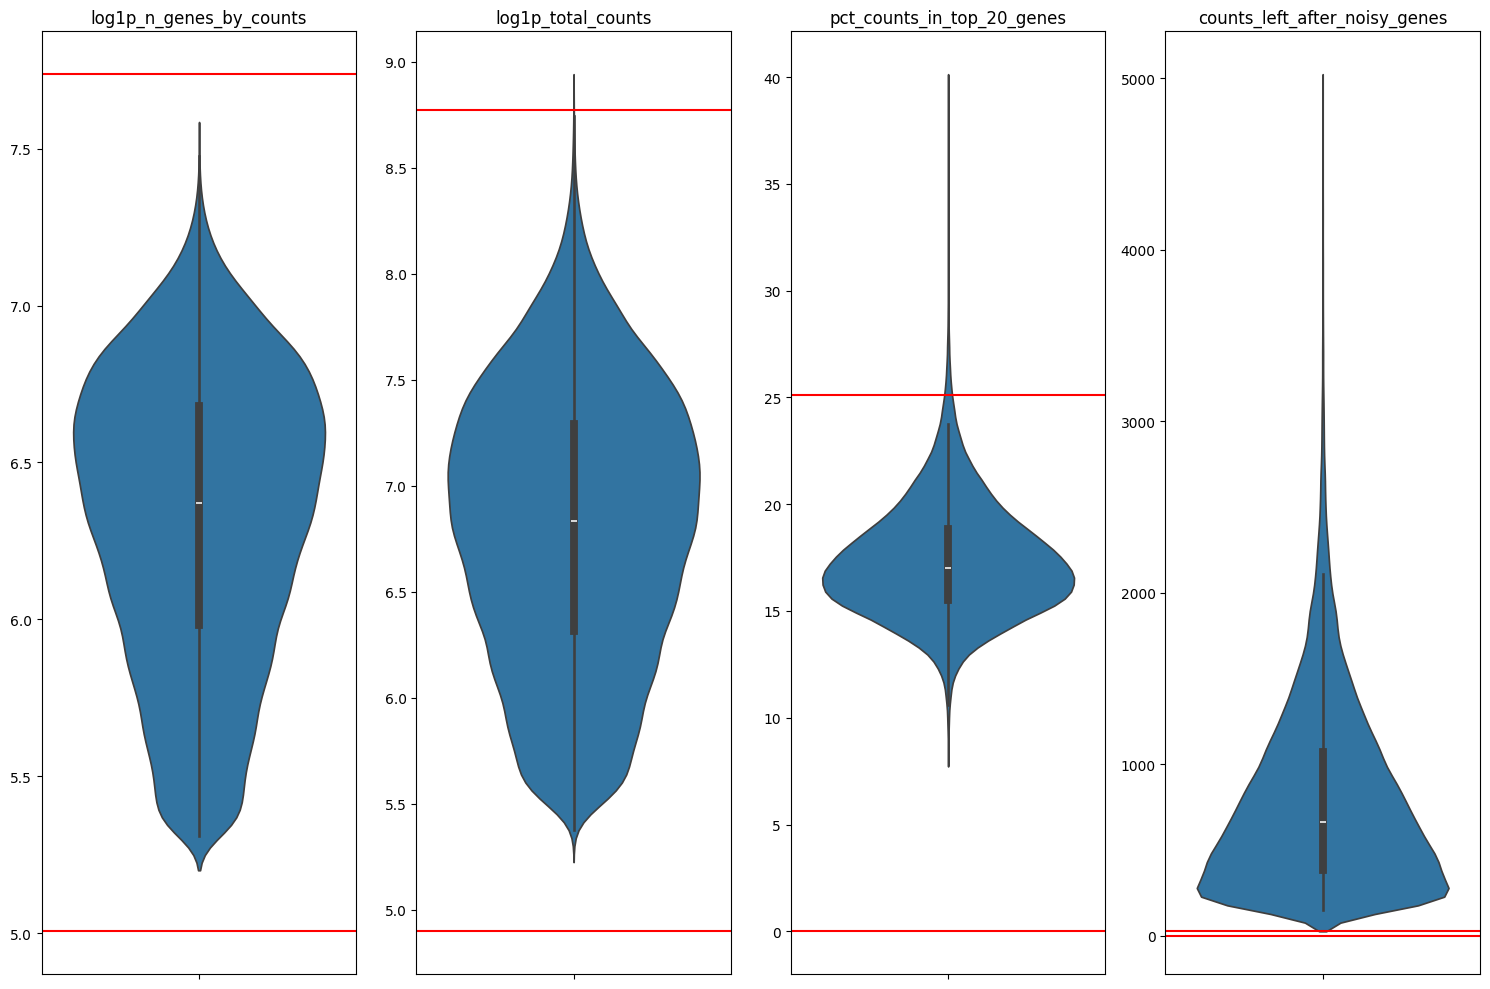

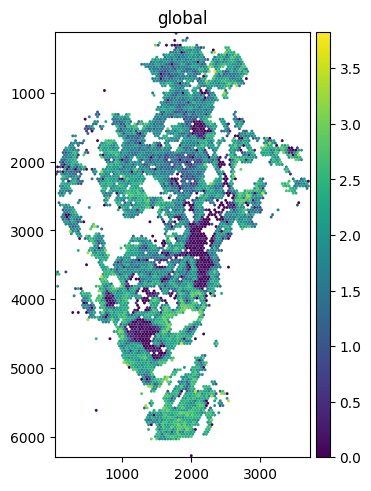

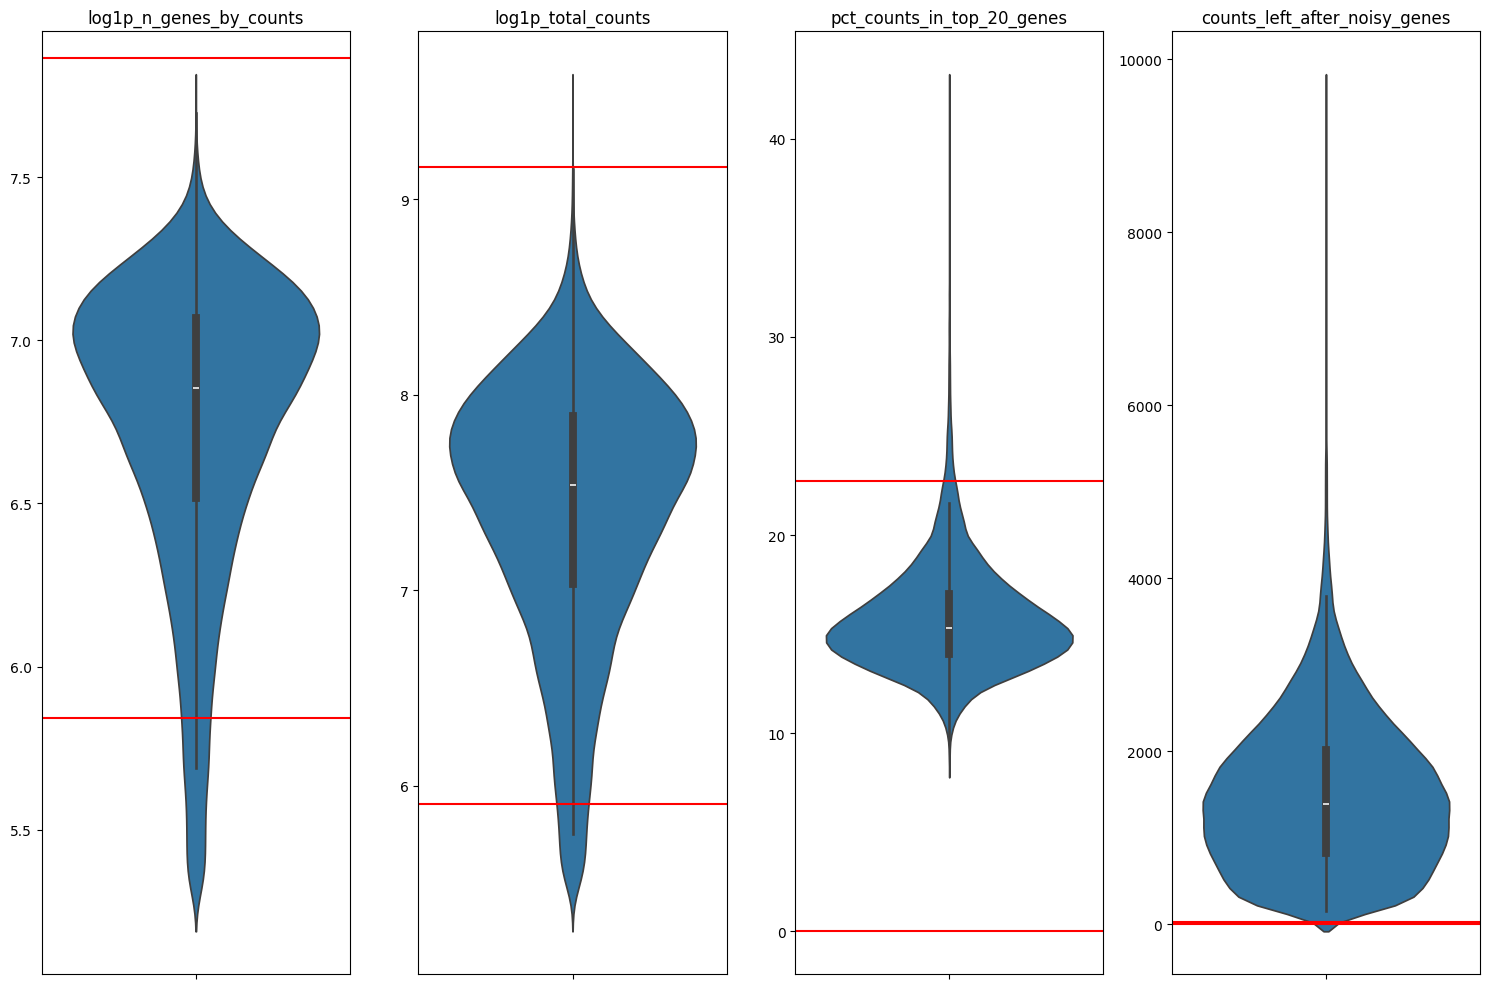

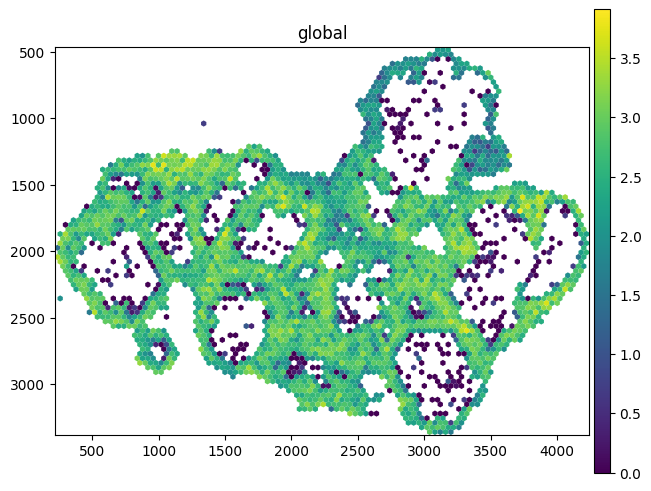

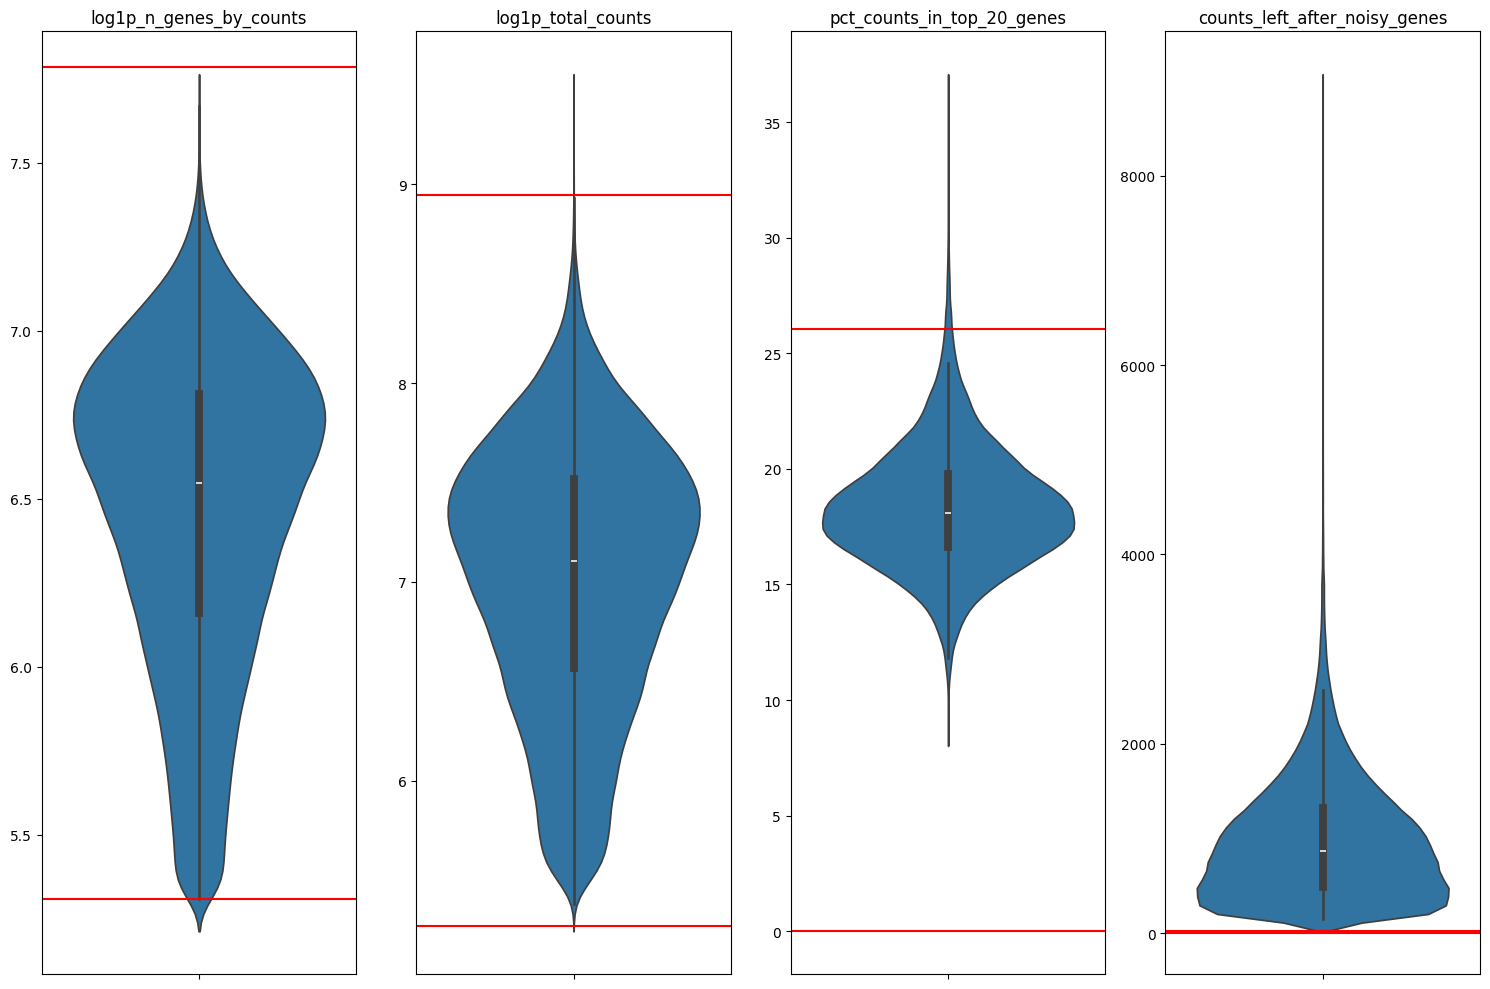

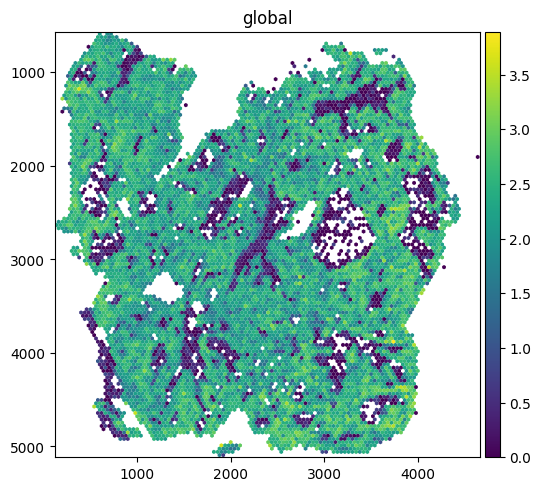

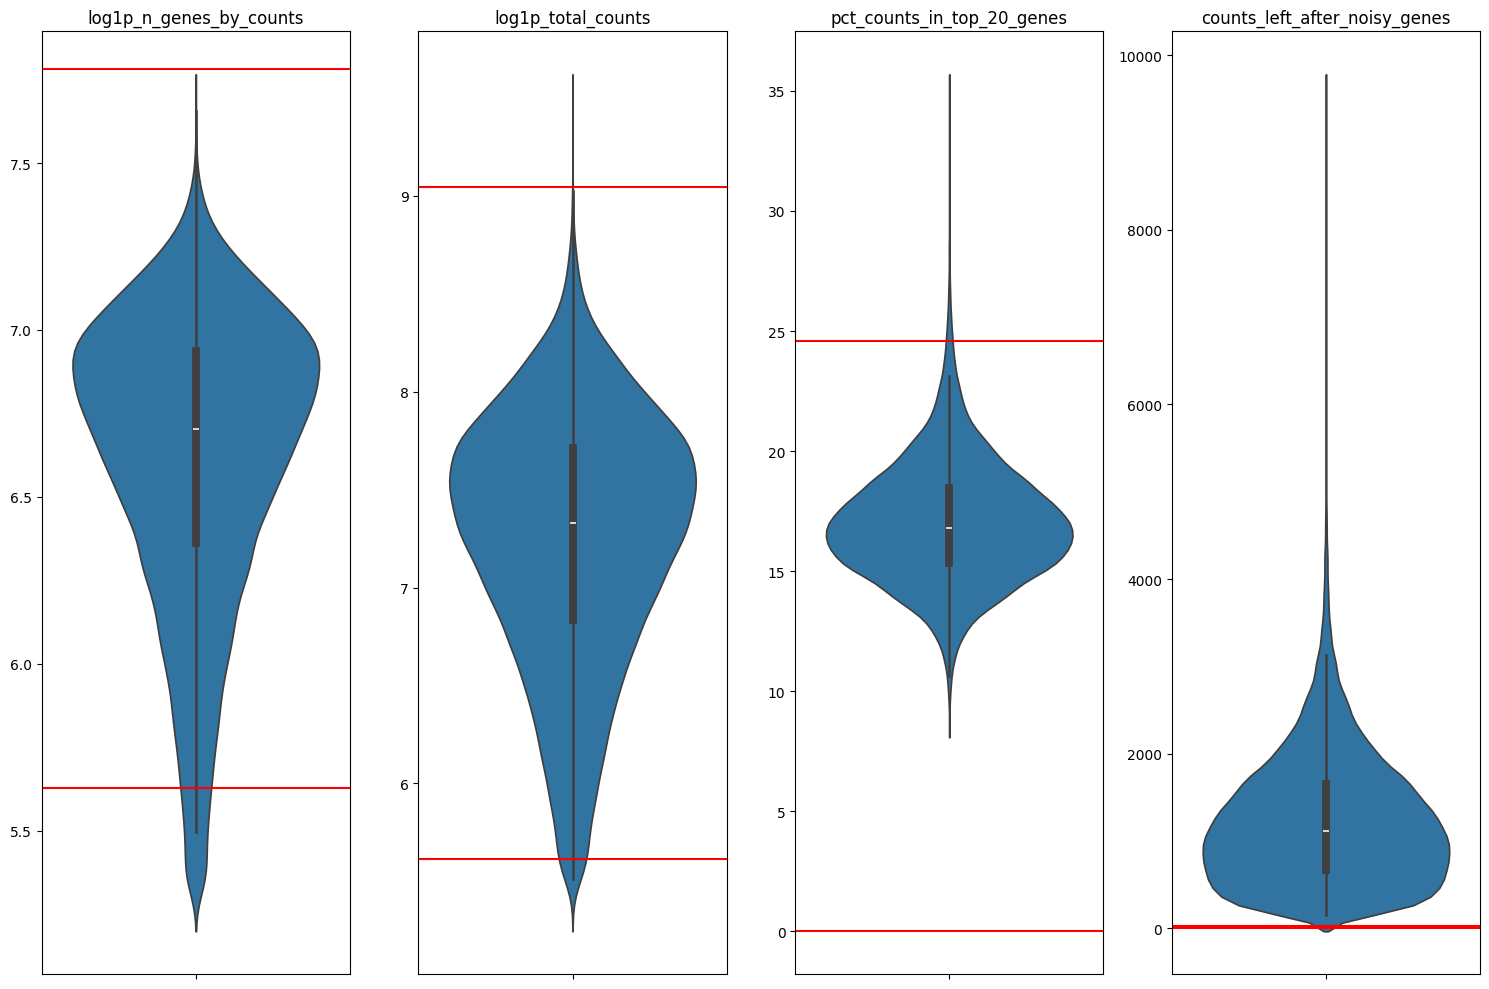

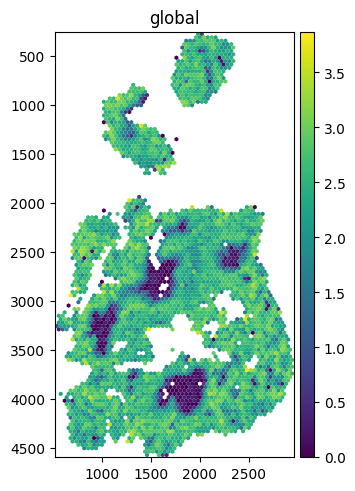

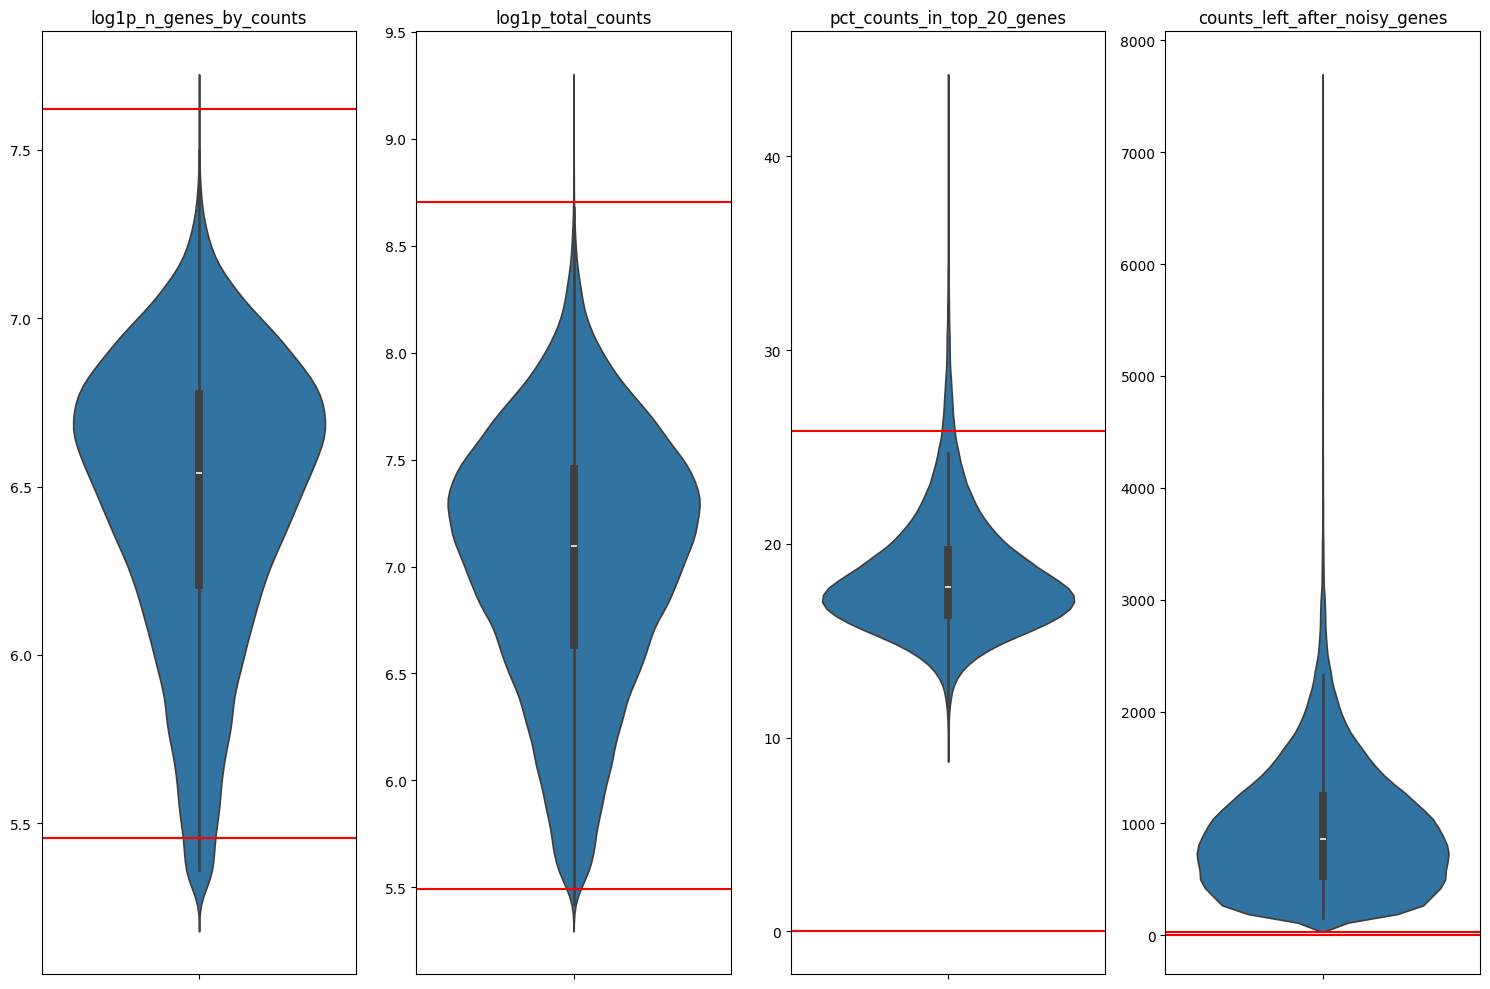

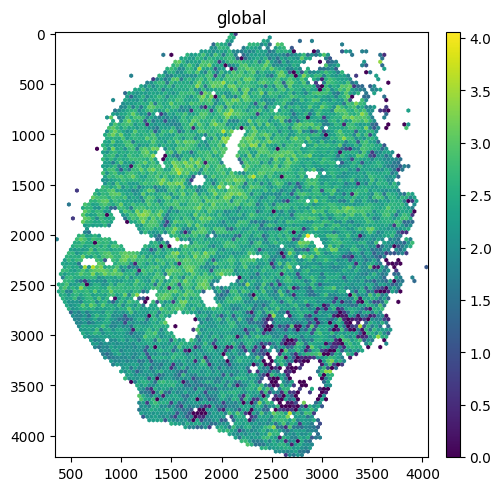

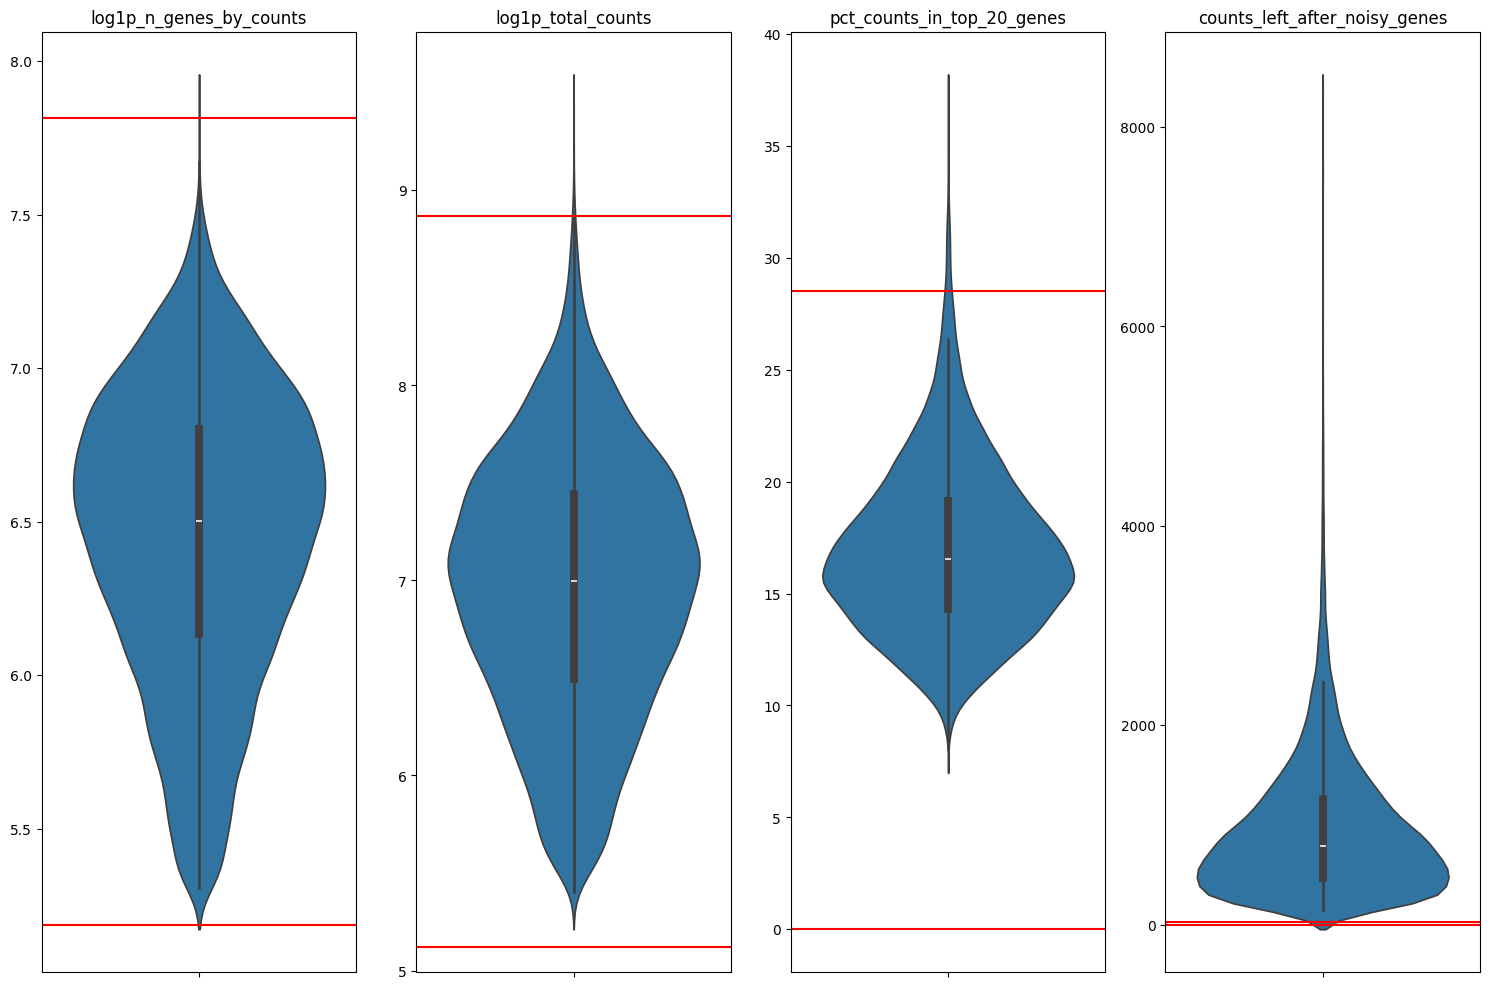

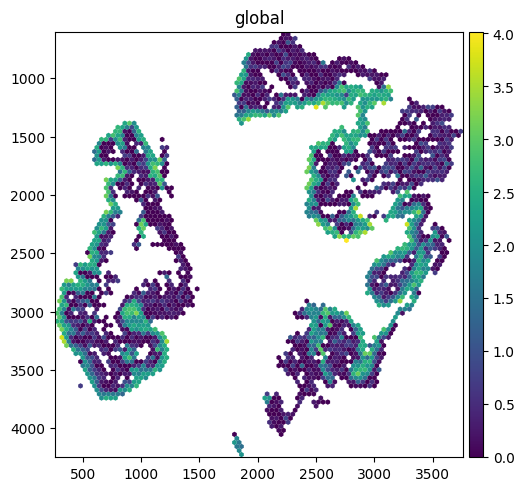

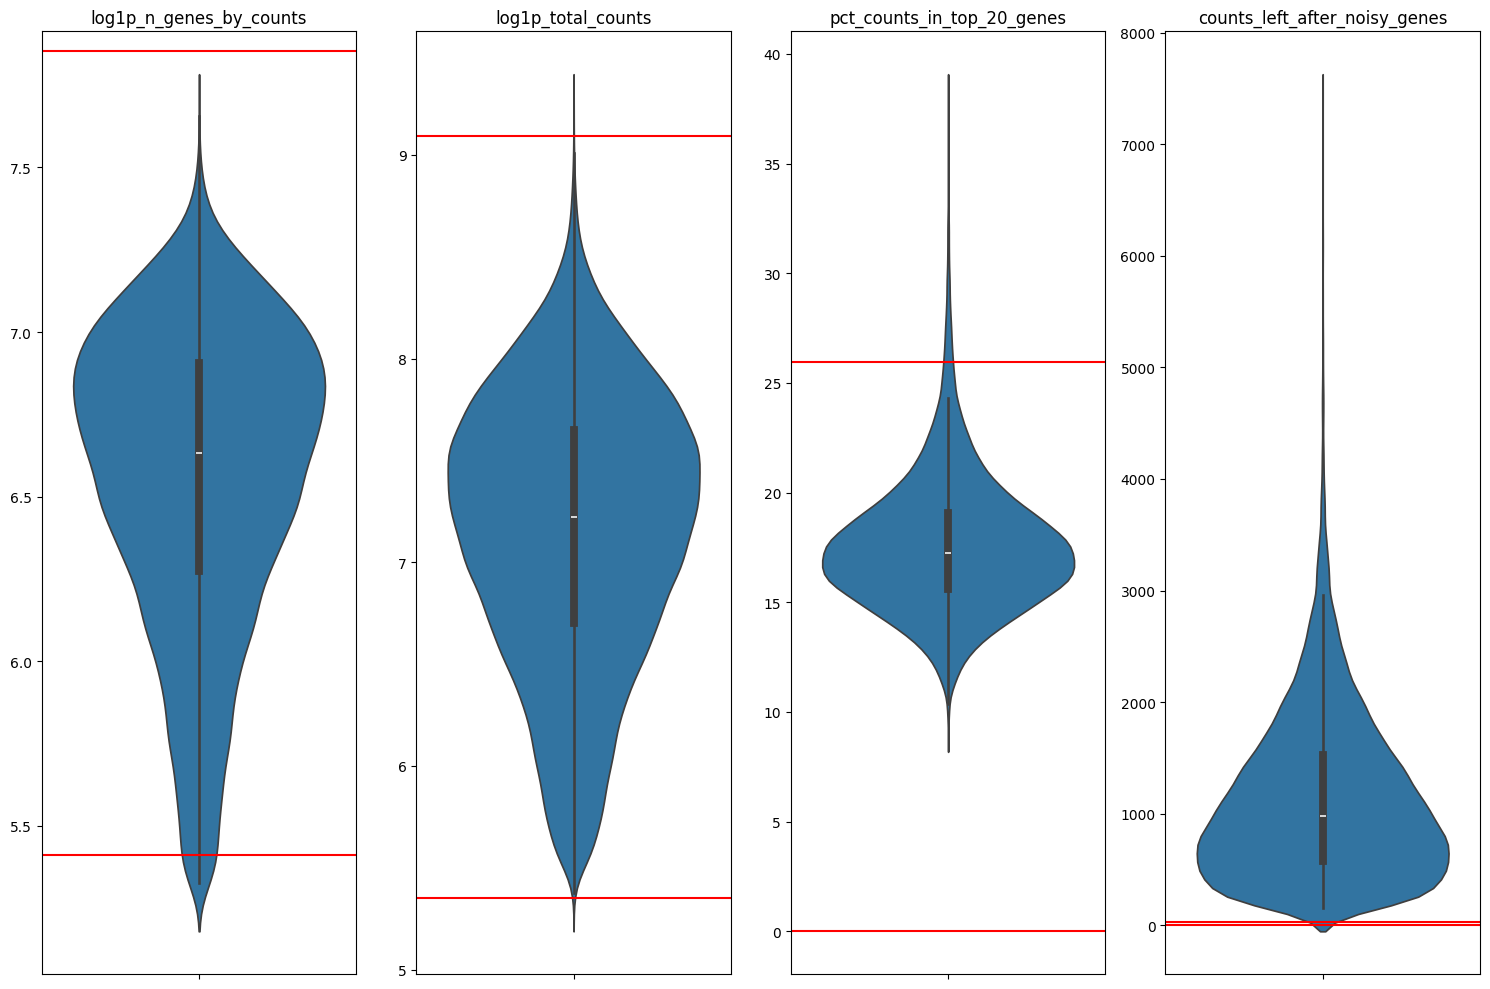

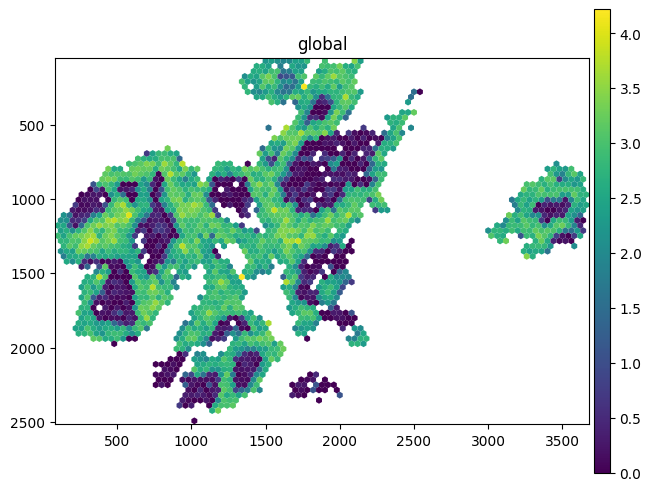

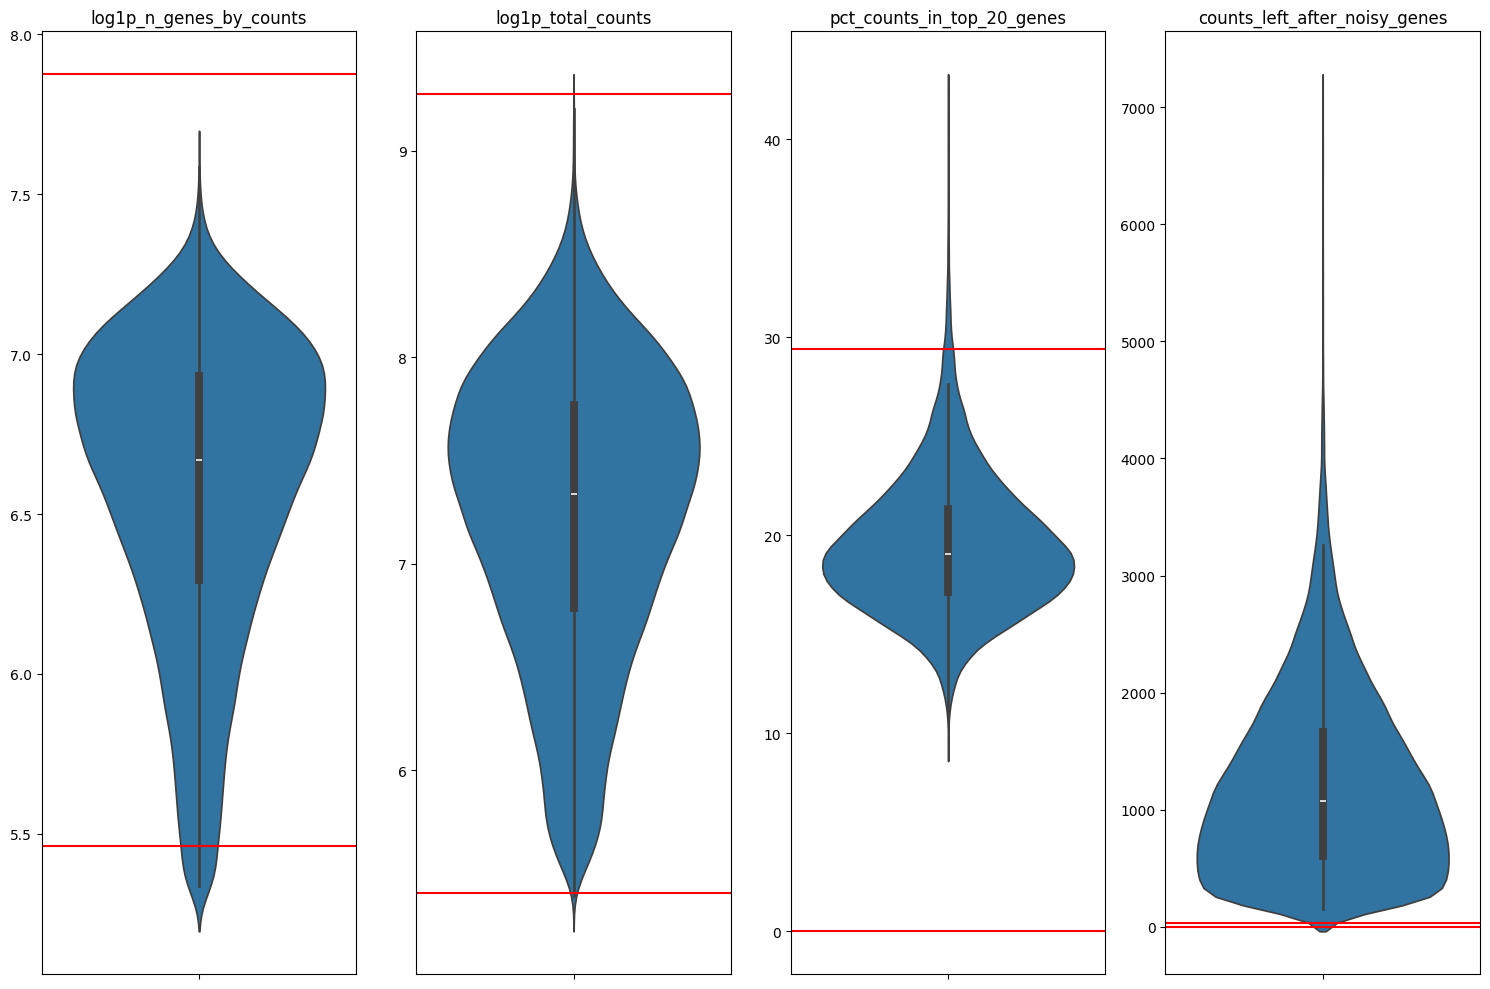

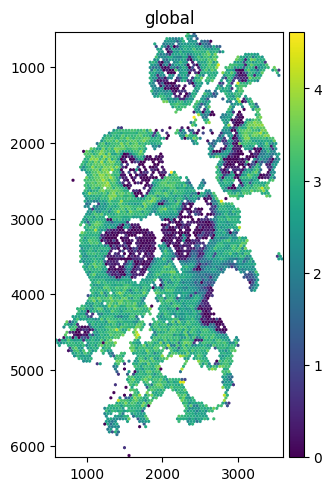

In [ ]:
import Pseudovisium.pseudovisium_generate as pvg


#if doesnt exist make folder processed_objects
if not os.path.exists(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects"):
  os.makedirs(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects")

for id in IDs:
  #make folder for ID if doesnt exist
  if not os.path.exists(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}"):
    os.makedirs(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}")

  #if os.path.exists(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/table.h5ad"):
    #continue

  #read zarr
  sdata = sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/{id}/processed_sd.zarr/")
  adata = sdata.tables["table"]
  adata = qc1(adata)
  adata, fig = qc2(adata)
  sdata.tables["table"] = adata
  fig.savefig(f"/content/drive/MyDrive/human_pcp/xenium/{id}/qc.png")

  tx_abundance = sdata["transcripts"].compute()["feature_name"].value_counts()

  #save as csv
  tx_abundance.to_csv(f"/content/drive/MyDrive/human_pcp/xenium/{id}/tx_abundance.csv")

  sdata["transcripts"].compute()

  tx_file = f"/content/drive/MyDrive/human_pcp/xenium/{id}/transcripts.parquet"

  pvg.generate_pv(
        csv_file=tx_file,
        bin_size=20,
        output_path=f"/content/drive/MyDrive/human_pcp/xenium/{id}/",
        batch_size=500000,
        technology="Xenium",
        max_workers=4
    )

  pvg.spatialdata_to_spatialdata(sdata, "table",
                                new_table_id= None,
                                new_shapes_id= None,
                                bin_size=20,
                                bin_type="hex")


  X = sdata.tables["table_PV_bins_20_hex"].X.copy()

  n_cells = sdata.tables["table_PV_bins_20_hex"].obs["n_cells"].to_numpy()

  # Reshape to (n_cells, 1) so it can broadcast correctly
  n_cells_reshaped = n_cells[:, np.newaxis]

  # Perform element-wise division safely
  X_normalized = X.multiply(1 / n_cells_reshaped)

  sdata.tables["table_PV_bins_20_hex"].X = X_normalized.toarray()
  #log1p
  sc.pp.log1p(sdata.tables["table_PV_bins_20_hex"])

  import spatialdata_plot
  sdata.pl.render_shapes("table_tessellation_20_hex", color="CLDN1",coordinate_system="global").pl.show()

  sdata.tables["table_PV_bins_20_hex"].obs["ID"] = id
  sdata.tables["table_PV_bins_20_hex"].uns.pop('original_adata_shape')
  sdata.tables["table"].obs["ID"] = id



  sdata.tables["table"].write(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/table.h5ad")
  #write zarr
  sdata.write(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr",overwrite=True)


# Assembling top 20 contaminating genes to filter out in celltyping/integration

In [ ]:
tables = []
for id in IDs:
  table_top = f"/content/drive/MyDrive/human_pcp/xenium/{id}/tx_abundance.csv"
  table_top = pd.read_csv(table_top,header=0)
  tables.append(table_top.head(50))

concat = pd.concat(tables)
#value_counts on feature_name
concat = concat["feature_name"].value_counts()
concat = concat.reset_index()
#keep those with larger count than 7
concat = concat[concat["count"]>6]
#save
concat.to_csv("/content/drive/MyDrive/human_pcp/xenium/top_contaminating_genes.csv")

# Loading back anndatas to concat for a shared final object

In [ ]:
adatas = []
for id in IDs:
  adata = sc.read(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/table.h5ad")
  adatas.append(adata)

In [ ]:
import squidpy as sq
adatas[0].uns["spatial"]={}
adatas[0].uns["spatial"]["library_id"] = "asd"

AnnData object with n_obs × n_vars = 45856 × 5001
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'counts_left_after_noisy_genes', 'ID'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'cells_removed', 'spatialdata_attrs'
    obsm: 'spatial'

In [ ]:
adatas_concat = anndata.concat(adatas, axis=0)

/usr/local/lib/python3.11/dist-packages/anndata/_core/anndata.py:1774: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [ ]:
#save adata_concat
adatas_concat.write(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/merged_adata_0613.h5ad")

# Loading in spatialdatas and concatting into a shared final sdata object

In [ ]:
sdatas = []
for id in IDs:
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))

/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/usr/local/lib/python3.11/dist-packages/zarr/creation.py:610: Use

In [ ]:
sdata_dict = dict(zip(IDs, sdatas))
sdatas_concat = sd.concatenate(sdata_dict,concatenate_tables=False, obs_names_make_unique=True)
sdatas_concat.write(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/merged_spatialdata.zarr")

In [ ]:
import spatialdata as sd
sdatas_concat = sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/merged_spatialdata.zarr/")

/usr/local/lib/python3.11/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.11/dist-packages/numba_cuda/numba/cuda/cudadrv/driver.py", line 314, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.11/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Failed to dlopen libcuda.so.1
  warnings.warn(str(e))


ValueError: len(nodes) = 0, expected 1. Unable to read the NGFF file. Please report this bug and attach a minimal data example.

# Spatial statistics on cell types - Supp Fig 5A Supp Fig 5B

In [ ]:
IDs = ["LYY", "CXM","CF","LYJ","HLY","WZY","LRS","YZB"]

In [ ]:
adatas = []
for id in IDs:
  adata = sc.read(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/table.h5ad")
  adatas.append(adata)

### Assigning cell types

In [ ]:
adata = sc.read("/content/drive/MyDrive/human_pcp/xenium/pcp_xenium_object_0618.h5ad")
obs_table = adata.obs

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:836: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  return read_h5ad(filename, backed=backed)


In [ ]:
obs_table
#mapping from cell_id to broad_cluster
mapping = obs_table[["cell_id","broad_cluster"]].set_index("cell_id")["broad_cluster"].to_dict()
mapping

{'aaacfede-1': 'Stem_like_cells',
 'aaaekeik-1': 'Stem_like_cells',
 'aaaenkcf-1': 'Stem_like_cells',
 'aaagedmj-1': 'Macrophages',
 'aaahfini-1': 'Epithelial_cells',
 'aaaibkob-1': 'T_cells',
 'aaakcmll-1': 'Stem_like_cells',
 'aaamgbcb-1': 'Epithelial_cells',
 'aaamhbfm-1': 'Stem_like_cells',
 'aaammpek-1': 'Stem_like_cells',
 'aaamplnj-1': 'Stem_like_cells',
 'aaanfogg-1': 'Stem_like_cells',
 'aabelbij-1': 'Stem_like_cells',
 'aabenjag-1': 'Stem_like_cells',
 'aabfkbmk-1': 'Stem_like_cells',
 'aabfndgh-1': 'Stem_like_cells',
 'aabhfcmo-1': 'Stem_like_cells',
 'aabhkhpj-1': 'Stem_like_cells',
 'aabiangm-1': 'Stem_like_cells',
 'aabicfen-1': 'Stem_like_cells',
 'aabihoak-1': 'Stem_like_cells',
 'aabnpnbk-1': 'Stem_like_cells',
 'aabogmmk-1': 'Stem_like_cells',
 'aabolpim-1': 'Epithelial_cells',
 'aaboobcb-1': 'Stem_like_cells',
 'aabppfgm-1': 'Epithelial_cells',
 'aacaadjb-1': 'Epithelial_cells',
 'aacaaokj-1': 'Epithelial_cells',
 'aacacbgn-1': 'Macrophages',
 'aacaebje-1': 'Stem_lik

In [ ]:
for adata in adatas:
  adata.obs["cell_type"] = adata.obs["cell_id"].map(mapping)

ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.
ERROR: Unable to fetch palette, reason: 'cell_type_colors'. Using `None`.


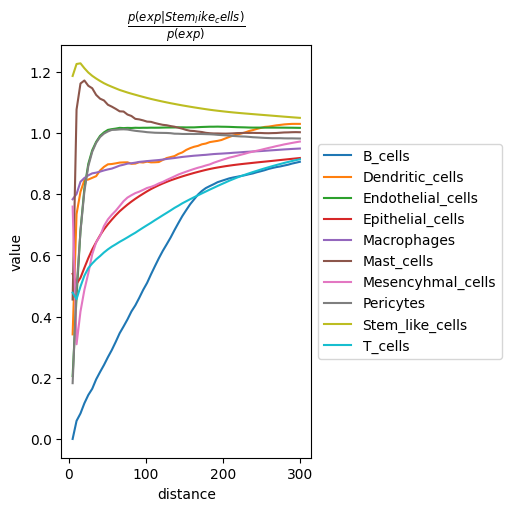

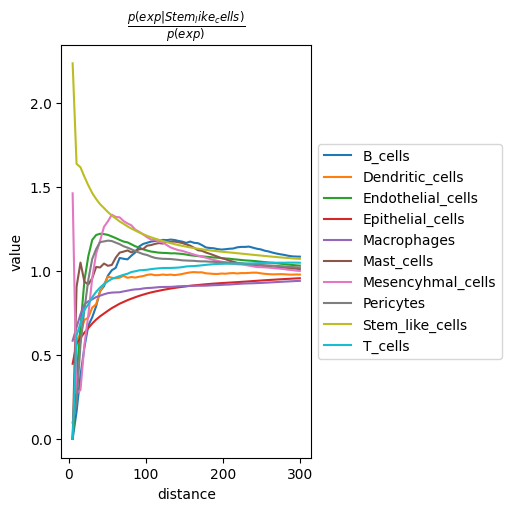

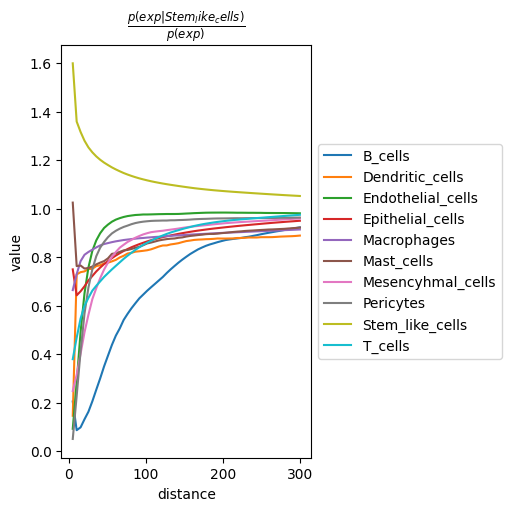

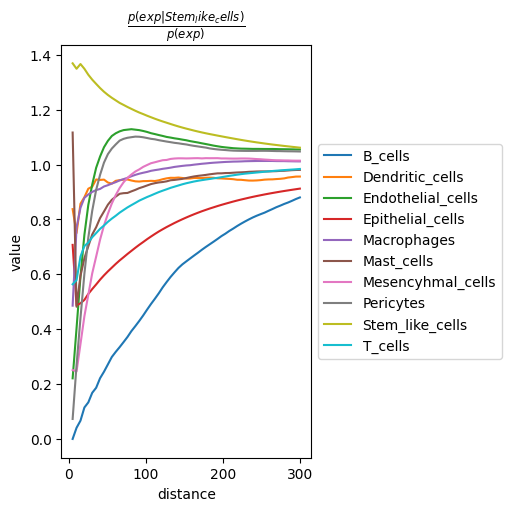

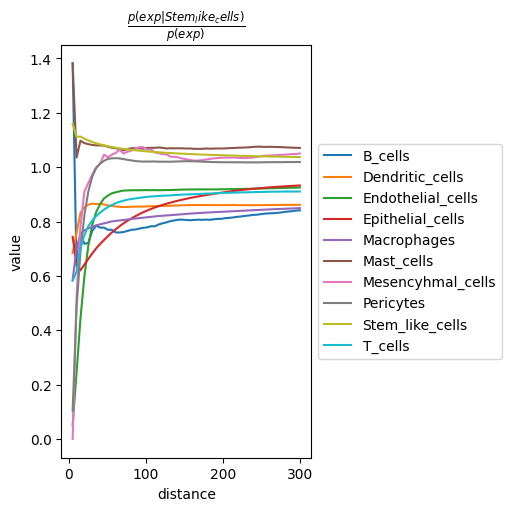

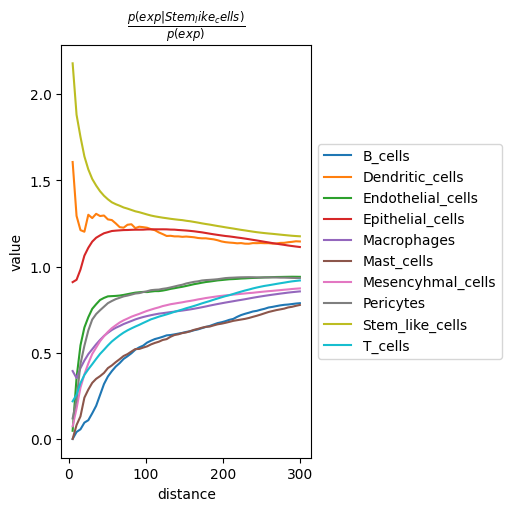

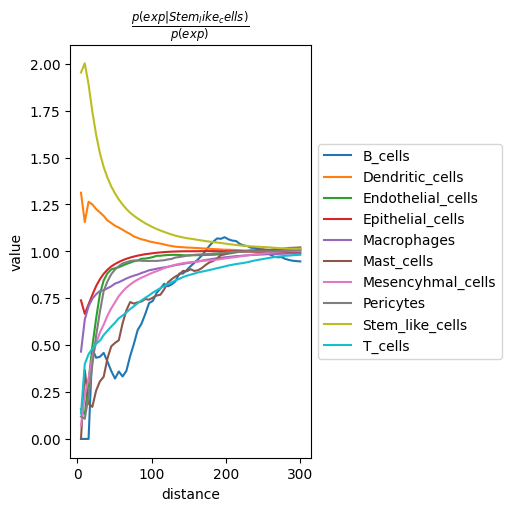

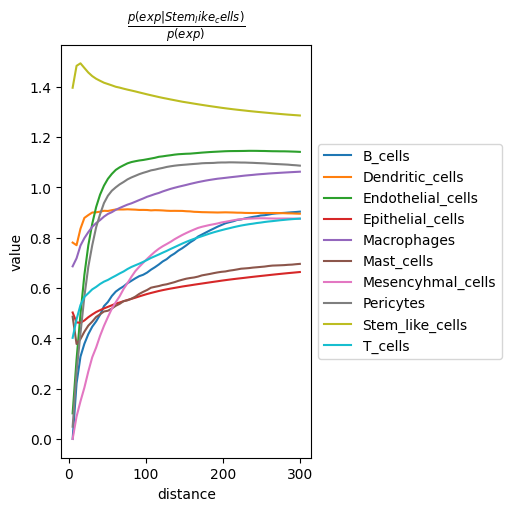

In [ ]:
import numpy as np
import squidpy as sq
for adata in adatas:
  interval = np.linspace(0,300,60)

  #turn cell_type to categorical
  adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

  sq.gr.co_occurrence(
      adata,
      cluster_key="cell_type",
      interval=interval
  )
  sq.pl.co_occurrence(
      adata,
      cluster_key="cell_type",
      clusters='Stem_like_cells',
  )

In [ ]:
#remove below:

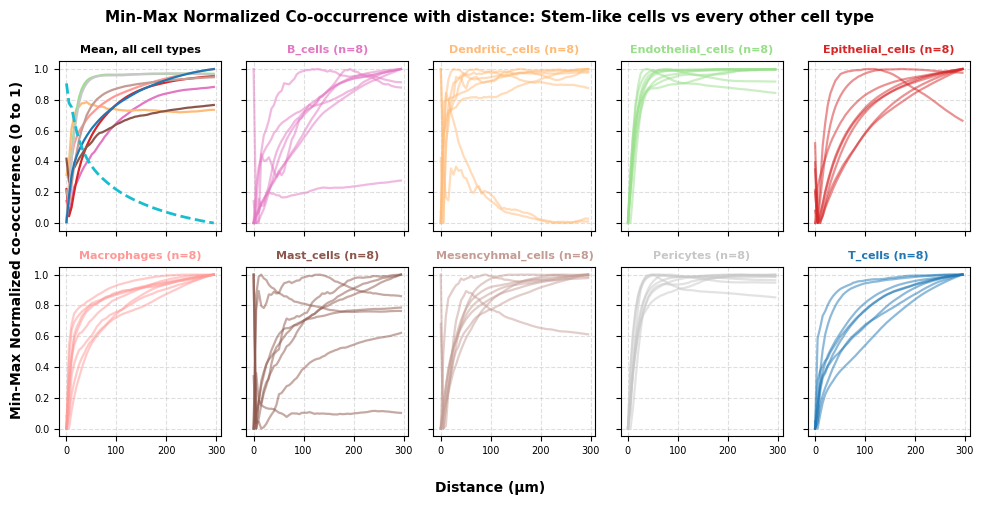

In [ ]:
import math
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Colors (unchanged)
palette = sns.color_palette("tab20", n_colors=20)
color_mapping = {
    "Stem_like_cells": 18, "Macrophages": 7, "Epithelial_cells": 6, "T_cells": 0,
    "Mast_cells": 10, "Endothelial_cells": 5, "Pericytes": 15,
    "Mesencyhmal_cells": 11, "Dendritic_cells": 3, "B_cells": 12,
    "Neutrophils": 13, "CD8 cytotoxic T-cells": 2, "CD4 T-cells": 0,
    "Naive B-cells": 12, "M2 Macrophages": 8, "M1 Macrophages": 7,
    "CD4 T-regs": 1, "pDC": 19, "Plasma cells": 17, "Pituicytes": 16,
}
colors_dict = {k: mcolors.to_hex(palette[v]) for k, v in color_mapping.items()}

target_cluster = "Stem_like_cells"
intervals = adatas[0].uns["cell_type_co_occurrence"]["interval"]
x_values = intervals[:-1]

# 2. Collect min-max normalized curves per cell type (one per dataset)
all_profiles = {}
for adata in adatas:
    categories = list(adata.obs["cell_type"].cat.categories)
    if target_cluster not in categories:
        continue
    cluster_idx = categories.index(target_cluster)
    occ = adata.uns["cell_type_co_occurrence"]["occ"]

    for other_idx, other_cell in enumerate(categories):
        curve = occ[cluster_idx, other_idx, :].copy()
        cmin, cmax = np.min(curve), np.max(curve)
        norm = (curve - cmin) / (cmax - cmin) if cmax > cmin else np.zeros_like(curve)
        all_profiles.setdefault(other_cell, []).append(norm)

# 3. Mean profiles (for the summary panel)
mean_profiles = {ct: np.mean(np.vstack(c), axis=0) for ct, c in all_profiles.items()}

# 4. Layout: slot 0 = mean summary, then one panel per non-target cell type
cell_types = sorted(c for c in all_profiles if c != target_cluster)
n_panels = len(cell_types) + 1
ncols = 5
nrows = math.ceil(n_panels / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 5), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

# --- Summary panel (old mean plot) ---
ax0 = axes[0]
for cell_type, mean_curve in mean_profiles.items():
    is_self = cell_type == target_cluster
    ax0.plot(
        x_values, mean_curve,
        color=colors_dict.get(cell_type, "#555555"),
        linewidth=2 if is_self else 1.6,
        linestyle="--" if is_self else "-",
        zorder=5 if is_self else 2,
    )
ax0.set_title("Mean, all cell types", fontsize=8, fontweight="bold")

# --- Per-cell-type panels ---
for ax, cell_type in zip(axes[1:], cell_types):
    line_color = colors_dict.get(cell_type, "#555555")
    for curve in all_profiles[cell_type]:
        ax.plot(x_values, curve, color=line_color, alpha=0.5, linewidth=1.6)
    ax.set_title(
        f"{cell_type} (n={len(all_profiles[cell_type])})",
        fontsize=8, fontweight="bold", color=line_color,
    )

# Shared styling
for ax in axes[:n_panels]:
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_ylim(-0.05, 1.05)
    ax.tick_params(labelsize=7)

for ax in axes[n_panels:]:
    ax.set_visible(False)

fig.supxlabel("Distance (µm)", fontsize=10, fontweight="bold")
fig.supylabel("Min-Max Normalized co-occurrence (0 to 1)", fontsize=10, fontweight="bold")
fig.suptitle(
    f"Min-Max Normalized Co-occurrence with distance: Stem-like cells vs every other cell type",
    fontsize=11, fontweight="bold",
)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/human_pcp/co_occurrence_panels.png", dpi=800)
plt.savefig("/content/drive/MyDrive/human_pcp/co_occurrence_panels.svg")
plt.show()

In [ ]:
for adata in adatas:
  sq.gr.spatial_neighbors(adata, delaunay=False, radius=50,coord_type = "generic")

  deg = np.diff(adata.obsp["spatial_connectivities"].indptr)
  print(f"mean {deg.mean():.1f}, median {np.median(deg):.0f}, zero-neighbor cells {(deg == 0).sum()}")

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_3275/1934964835.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, delaunay=False, radius=50,coord_type = "generic")


mean 56.0, median 55, zero-neighbor cells 42
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_3275/1934964835.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, delaunay=False, radius=50,coord_type = "generic")


mean 38.2, median 38, zero-neighbor cells 71
INFO     Creating graph using `None` transform and `1` libraries.                                                  


...

mean 45.5, median 46, zero-neighbor cells 3
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_3275/1934964835.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, delaunay=False, radius=50,coord_type = "generic")


mean 54.2, median 55, zero-neighbor cells 6
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_3275/1934964835.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, delaunay=False, radius=50,coord_type = "generic")


mean 46.8, median 44, zero-neighbor cells 15


  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 0 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Stem_like_cells      26271             60.31
Epithelial_cells     12297             49.29
T_cells               2710             50.16
Endothelial_cells     1762             52.08
Macrophages           1634             56.77
Pericytes              649             53.85
Mesencyhmal_cells      299             38.62
B_cells                112             39.28
Mast_cells              66             62.59
Dendritic_cells         56             59.45



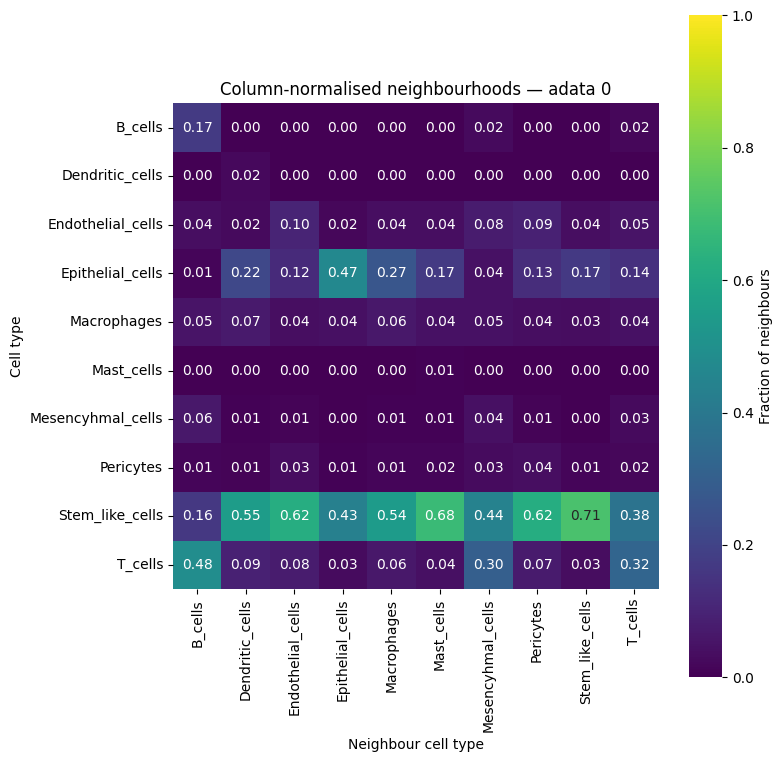

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 1 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Epithelial_cells     10563             38.21
Stem_like_cells       6799             41.20
Macrophages           1786             34.88
T_cells                643             36.20
Endothelial_cells      633             31.43
Pericytes              555             30.92
Mesencyhmal_cells      181             10.43
Dendritic_cells         44             38.34
Mast_cells              37             23.81
B_cells                 24             23.46



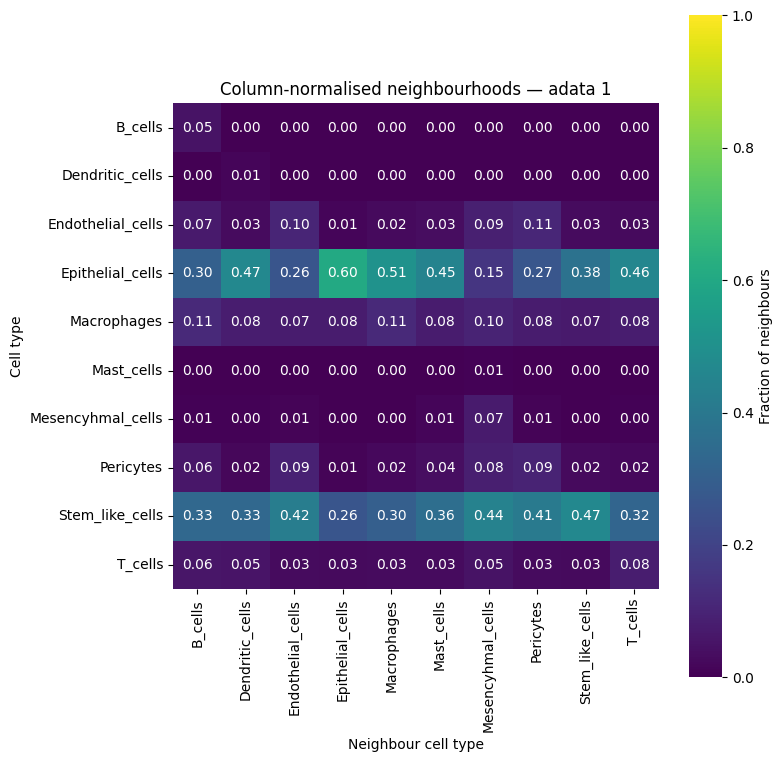

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 2 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Stem_like_cells      37785             56.45
Epithelial_cells     21349             49.37
Macrophages           7351             49.18
Endothelial_cells     4846             47.71
T_cells               3781             48.16
Pericytes             2676             47.11
Mesencyhmal_cells     1751             38.31
B_cells                281             38.55
Mast_cells             202             47.72
Dendritic_cells        155             55.40



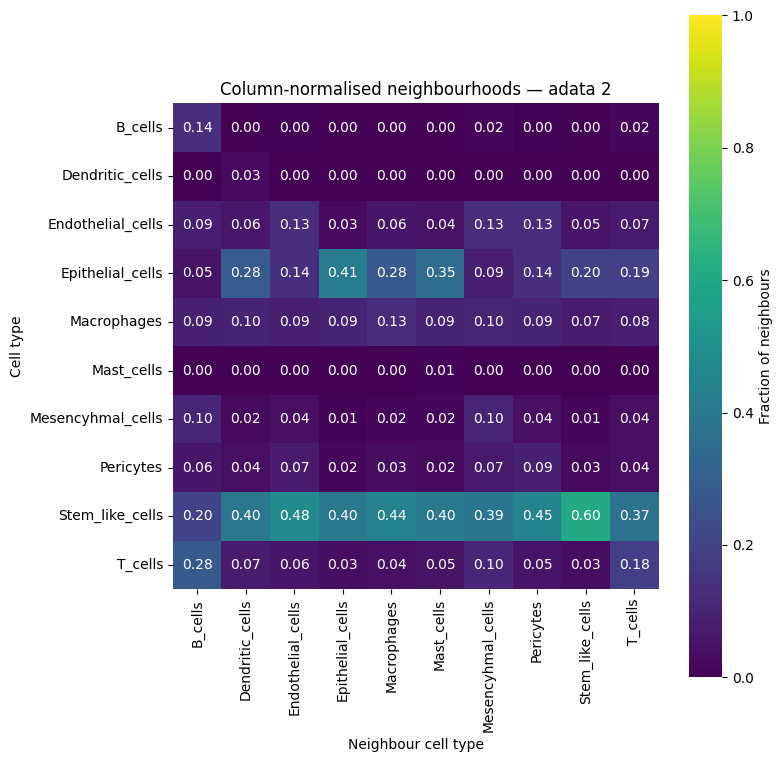

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 3 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Stem_like_cells      13291             66.03
Epithelial_cells     12019             41.82
T_cells               1545             59.17
Macrophages           1489             54.62
Endothelial_cells     1178             62.27
Pericytes              714             61.96
Mesencyhmal_cells      427             54.47
Mast_cells             142             47.99
B_cells                 99             54.92
Dendritic_cells         59             57.39



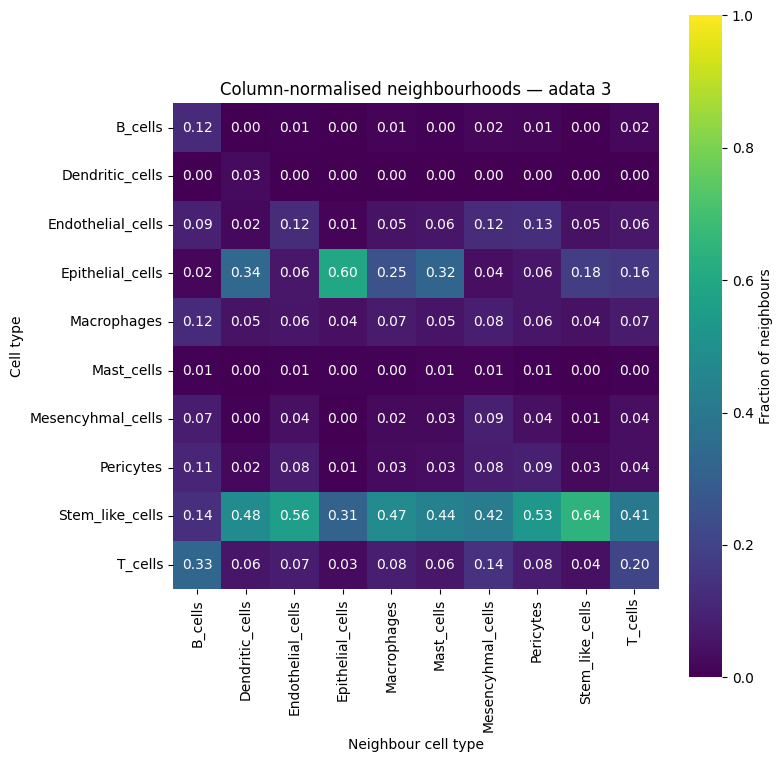

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 4 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Stem_like_cells      50013             68.92
Epithelial_cells     11248             55.00
Macrophages           5743             58.82
T_cells               2230             58.36
Endothelial_cells     1972             55.66
Dendritic_cells       1232             58.11
Pericytes              693             62.51
Mast_cells              39             70.21
B_cells                 36             51.58
Mesencyhmal_cells        8             64.12



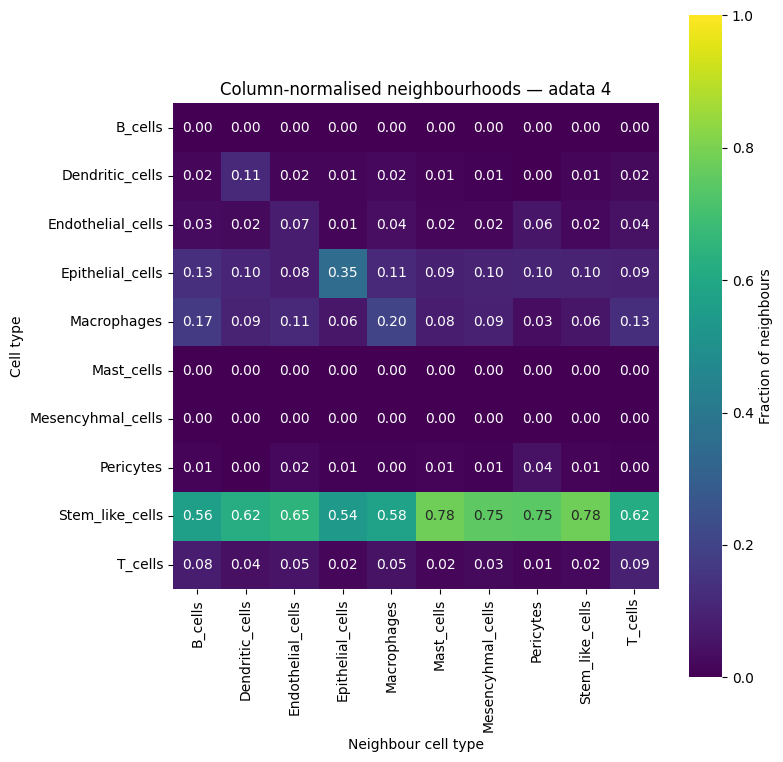

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 5 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Macrophages           4633             34.13
Stem_like_cells       3930             57.81
Epithelial_cells      2962             56.05
Mesencyhmal_cells     1590             38.82
T_cells               1422             37.24
Endothelial_cells      644             43.96
Pericytes              412             40.88
B_cells                126             37.14
Mast_cells             103             34.06
Dendritic_cells         27             54.89



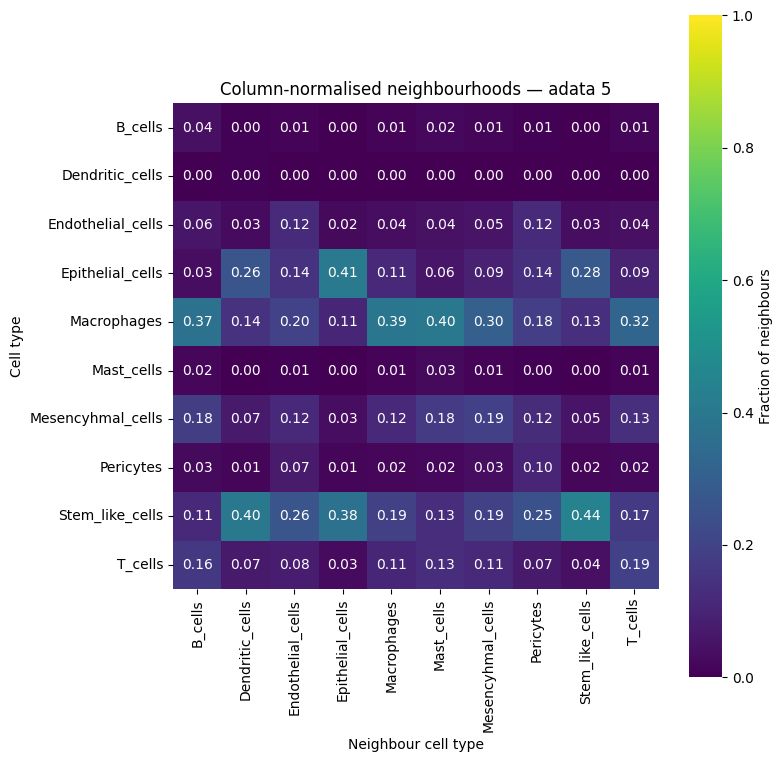

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 6 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Epithelial_cells      7745             58.28
Stem_like_cells       4297             57.07
Macrophages           2010             49.37
Mesencyhmal_cells     1767             40.54
Dendritic_cells        863             59.55
T_cells                601             47.19
Endothelial_cells      554             43.89
Pericytes              542             44.27
Mast_cells              14             40.14
B_cells                  5             34.40



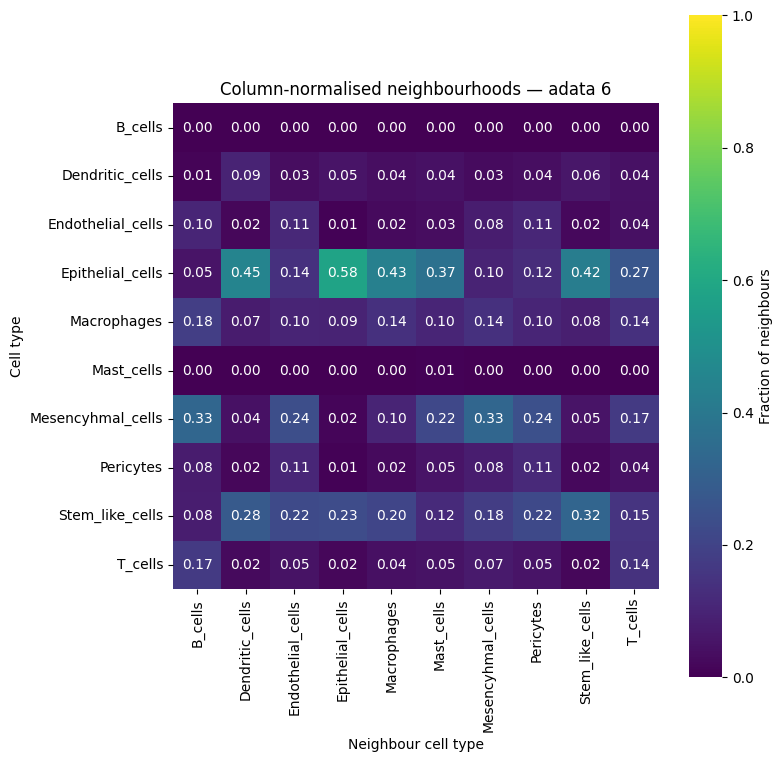

  0%|          | 0/1000 [00:00<?, ?/s]

=== adata 7 ===
                   n_cells  mean_n_neighbors
cell_type                                   
Stem_like_cells      14315             55.81
Epithelial_cells     14197             41.68
Macrophages           1944             39.53
Endothelial_cells     1422             40.23
T_cells               1258             42.27
Dendritic_cells        964             46.57
Pericytes              898             38.61
Mesencyhmal_cells      711             25.34
B_cells                197             34.23
Mast_cells             194             40.51



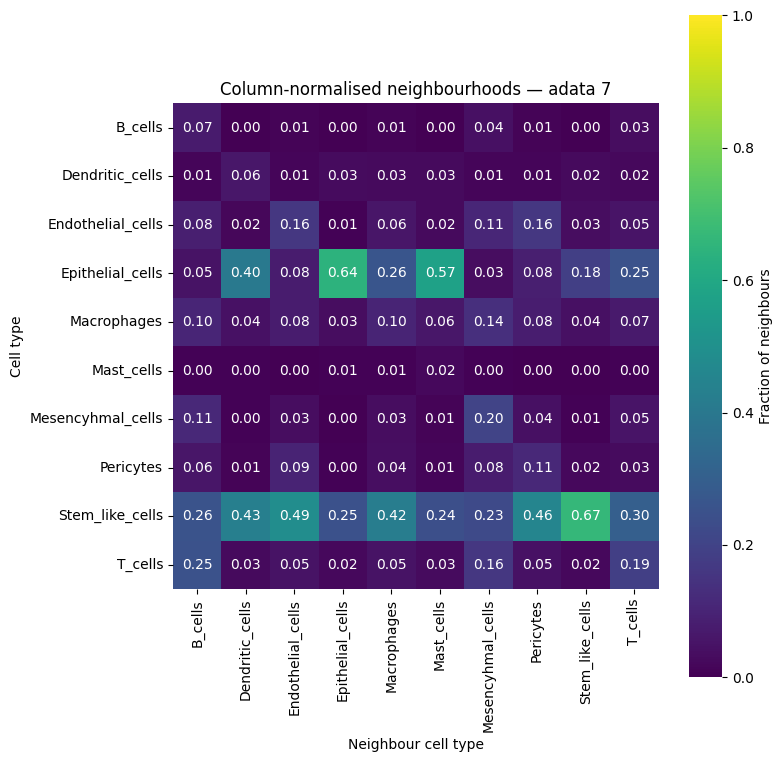

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squidpy as sq

col_norm_dfs = []

for i, adata in enumerate(adatas):

    sq.gr.nhood_enrichment(
        adata,
        cluster_key="cell_type",
    )

    count = adata.uns["cell_type_nhood_enrichment"]["count"]

    # Column-normalise
    col_norm = count / count.sum(axis=0, keepdims=True)

    labels = adata.obs["cell_type"].cat.categories

    # Keep a labelled copy for averaging later
    col_norm_dfs.append(pd.DataFrame(col_norm, index=labels, columns=labels))

    # Cell counts and mean number of spatial neighbours per cell type
    conn = adata.obsp["spatial_connectivities"]
    n_neighbors = np.asarray((conn > 0).sum(axis=1)).ravel()

    summary = pd.DataFrame({
        "n_cells": adata.obs["cell_type"].value_counts(),
        "mean_n_neighbors": pd.Series(n_neighbors, index=adata.obs_names)
                              .groupby(adata.obs["cell_type"], observed=True)
                              .mean()
                              .round(2),
    }).sort_values("n_cells", ascending=False)

    print(f"=== adata {i} ===")
    print(summary.to_string())
    print()

    plt.figure(figsize=(8, 8))

    sns.heatmap(
        col_norm,
        xticklabels=labels,
        yticklabels=labels,
        cmap="viridis",
        vmin=0,
        vmax=1,
        square=True,
        annot=True,
        fmt=".2f",
        cbar_kws={"label": "Fraction of neighbours"},
    )

    plt.title(f"Column-normalised neighbourhoods — adata {i}")
    plt.xlabel("Neighbour cell type")
    plt.ylabel("Cell type")
    plt.tight_layout()
    plt.show()



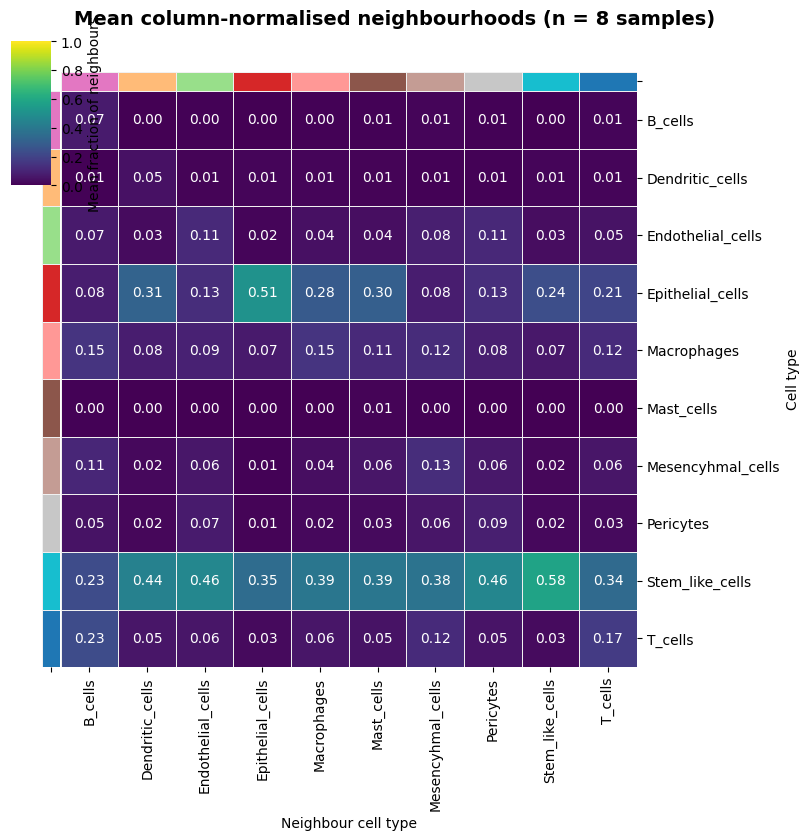

In [ ]:
import os

# Align all matrices on the union of cell types, then take the element-wise mean
all_labels = sorted(set().union(*[df.index for df in col_norm_dfs]))
aligned = [df.reindex(index=all_labels, columns=all_labels) for df in col_norm_dfs]

stacked = np.stack([df.values for df in aligned])      # (n_samples, n_types, n_types)
mean_norm = np.nanmean(stacked, axis=0)                # ignore samples missing a type
n_present = np.sum(~np.isnan(stacked), axis=0)         # how many samples contributed

mean_df = pd.DataFrame(mean_norm, index=all_labels, columns=all_labels)

# Row/column colour annotations (same mapping as the Z-score plot)
type_colors = pd.Series(all_labels, index=all_labels).map(colors_dict).fillna("#ffffff")

g = sns.clustermap(
    mean_df,
    row_cluster=False,
    col_cluster=False,
    cmap="viridis",
    vmin=0,
    vmax=1,
    figsize=(8, 8),
    row_colors=type_colors,
    col_colors=type_colors,
    dendrogram_ratio=0.05,
    colors_ratio=0.03,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="#f0f0f0",
    cbar_kws={"label": "Mean fraction of neighbours"},
)

g.ax_heatmap.set_xlabel("Neighbour cell type")
g.ax_heatmap.set_ylabel("Cell type")
g.figure.suptitle(
    f"Mean column-normalised neighbourhoods (n = {len(col_norm_dfs)} samples)",
    y=1.02,
    fontsize=14,
    fontweight="bold",
)

out_dir = "/content/drive/MyDrive/human_pcp/"
os.makedirs(out_dir, exist_ok=True)
g.savefig(os.path.join(out_dir, "mean_nhood_col_norm.svg"), bbox_inches="tight")
g.savefig(os.path.join(out_dir, "mean_nhood_col_norm.png"), dpi=300, bbox_inches="tight")
plt.show()

if (n_present < len(col_norm_dfs)).any():
    print("Note: some cell types are missing in some samples; those entries "
          "are averaged over fewer samples:")
    print(pd.DataFrame(n_present, index=all_labels, columns=all_labels).to_string())

# Pseudobulk analysis

In [ ]:
!pip install openpyxl
!pip install decoupler==1.8.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 12.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.3/126.3 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 159.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 218.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 MB 118.2 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.48.0
    Uninstalling llvmlite-0.48.0:
      Successfully uninstalled llvmlite-0.48.0
  Attempting uninstall: numba
    Found existing installation: numba 0.66.0
    Uninstalling numba-0.66.0:
      Successfully uninstalled numba-0.66.0
ERROR: pip's dependency resolver does not currently take i

In [ ]:
import decoupler as dc
import scanpy as sc

In [ ]:
adata = sc.read("/content/drive/MyDrive/human_pcp/xenium/pcp_xenium_object_0618.h5ad")
adata

/usr/local/lib/python3.12/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 321822 × 4418
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'counts_left_after_noisy_genes', 'ID', '_scvi_batch', '_scvi_labels', 'leiden_scVI', '_scvi_raw_norm_scaling', 'broad_cluster'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'broad_cluster_colors', 'leiden_scVI', 'leiden_scVI_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'

In [ ]:
import pandas as pd
import numpy as np

# Add Series.nonzero if missing
if not hasattr(pd.Series, "nonzero"):
    pd.Series.nonzero = lambda self: np.asarray(self).nonzero()

In [ ]:
pdata = dc.get_pseudobulk(
    adata,
    sample_col="ID",
    groups_col="broad_cluster",
    mode="sum",
    min_cells=25,
    min_counts=0
)

In [ ]:
pdata

AnnData object with n_obs × n_vars = 76 × 4418
    obs: 'ID', 'broad_cluster', 'region', '_scvi_batch', '_scvi_labels', 'psbulk_n_cells', 'psbulk_counts'
    var: 'n_cells'
    layers: 'psbulk_props'

In [ ]:
pdata.obs = pdata.obs.astype(str)
pdata.var = pdata.var.astype(str)

In [ ]:
#write
pdata.write("/content/drive/MyDrive/human_pcp/xenium/xenium_pseudobulk.h5ad")

# Making Spatial figures

In [6]:
!pip install openpyxl
!pip install decoupler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.4/147.4 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 17.4 MB/s eta 0:00:00


In [7]:
!pip install zarr spatialdata spatialdata-io --upgrade

  Using cached spatialdata-0.8.0-py3-none-any.whl.metadata (10 kB)
  Using cached ome_zarr-0.21.0-py3-none-any.whl.metadata (3.1 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.6/202.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.0/66.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 463.6/463.6 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 99.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 6.1 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.50.1
    Uninstalling pydantic_core-2.50.1:
      Successfully uninstalled

In [7]:
import decoupler as dc
import numpy as np

In [8]:
#/content/drive/MyDrive/human_pcp/smallridge_thyroid_degs.xlsx
import pandas as pd
smallridge_df = pd.read_excel("/content/drive/MyDrive/human_pcp/smallridge_thyroid_degs.xlsx",header=1)
#keep only Gene Symbol, logFC and p-value
smallridge_df = smallridge_df[['Gene Symbol', 'logFC', 'p-value']]
#rename to gene, fc, pval
smallridge_df.columns = ['gene', 'fold_change', 'p_value']
#dataset
smallridge_df['dataset'] = 'smallridge'
smallridge_up_genes = smallridge_df[smallridge_df['fold_change'] > 0]
smallridge_down_genes = smallridge_df[smallridge_df['fold_change'] < 0]
smallridge_df.head()

,gene,fold_change,p_value,dataset
0,ABCA10,-1.436412,0.007684,smallridge
1,ABCC8,-1.384465,0.003453,smallridge
2,ACAP1,-1.957668,0.000221,smallridge
3,ACTA2,-0.845268,0.006913,smallridge
4,ADAM19,-1.398811,0.006118,smallridge


In [2]:
import spatialbk as sbk
import spatialdata as sd
import anndata
import pandas as pd
import scanpy as sc
import os

In [3]:
IDs = ["CXM","LYY","CF","LYJ","HLY","WZY","LRS","YZB"]
sdatas = []
for id in IDs:
  print(id)
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))

CXM


/tmp/ipykernel_4554/4085450375.py:5: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))


LYY


/tmp/ipykernel_4554/4085450375.py:5: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))


CF


...

/tmp/ipykernel_4554/4085450375.py:5: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))


LRS


/tmp/ipykernel_4554/4085450375.py:5: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))


YZB


/tmp/ipykernel_4554/4085450375.py:5: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdatas.append(sd.read_zarr(f"/content/drive/MyDrive/human_pcp/xenium/processed_objects/{id}/processed_sd.zarr/"))


In [4]:
adata = sc.read("/content/drive/MyDrive/human_pcp/xenium/pcp_xenium_object_0618.h5ad")
obs_table = adata.obs
#in mapping change Mesencyhmal_cells to Mesenchymal_cells
obs_table["broad_cluster"] = obs_table["broad_cluster"].replace("Mesencyhmal_cells", "Mesenchymal_cells")
mapping = obs_table[["cell_id","broad_cluster"]].set_index("cell_id")["broad_cluster"].to_dict()


/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:836: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  return read_h5ad(filename, backed=backed)
/tmp/ipykernel_4554/362879386.py:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  obs_table["broad_cluster"] = obs_table["broad_cluster"].replace("Mesencyhmal_cells", "Mesenchymal_cells")


In [5]:
for sdata in sdatas:
  sdata.tables["table"].obs["region"] = "cell_boundaries"
  sdata.set_table_annotates_spatialelement("table", region="cell_boundaries")

  sdata.tables["nucleus_table"] = sdata.tables["table"].copy()
  sdata.tables["nucleus_table"].obs["region"] = "nucleus_boundaries"
  sdata.set_table_annotates_spatialelement("nucleus_table", region="nucleus_boundaries")

  sdata.tables["table"].obs["cell_type"] = sdata.tables["table"].obs["cell_id"].map(mapping)
  sc.pp.log1p(sdata.tables["table"])

/usr/local/lib/python3.13/dist-packages/spatialdata/_core/spatialdata.py:477: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)
/usr/local/lib/python3.13/dist-packages/spatialdata/_core/spatialdata.py:477: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)
/usr/local/lib/python3.13/dist-packages/spatialdata/_core/spatialdata.py:477: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)
/usr/local/lib/python3.13/dist-packages/spatialdata/_core/spatialdata.py:477: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)
/usr/local/lib/python3.13/dist-packages/spatialdata/_core/spatialdata.py:477: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)
/usr/local/lib/python3.13/dist-packages/spati

In [9]:
import numpy as np
import pandas as pd
import decoupler as dc

# Build one net with both signatures
net = pd.concat([
    pd.DataFrame({"source": "BRAF_up",   "target": smallridge_up_genes["gene"]}),
    pd.DataFrame({"source": "BRAF_down", "target": smallridge_down_genes["gene"]}),
]).drop_duplicates()

def clip_percentiles(s, lo=2.5, hi=97.5):
    lower, upper = np.percentile(s, [lo, hi])
    return s.clip(lower=lower, upper=upper)

for sdata in sdatas:
    adata = sdata.tables["table"]

    dc.mt.aucell(adata, net, tmin=5, raw=False, verbose=False)

    scores = adata.obsm["score_aucell"]  # DataFrame: cells x sources
    adata.obs["aucell_braf_up"]   = clip_percentiles(scores["BRAF_up"])
    adata.obs["aucell_braf_down"] = clip_percentiles(scores["BRAF_down"])

In [10]:
gene_pairs = [
    #["ANXA2","FPR1"],
    #["ANXA2","ROBO4"],
    #["ANXA2","TLR2"],
    ["CXCL6","CXCR2"],
    #["CD44","LAMC2"],
   # ["CD44","HBEGF"],
    #["CD44","PKM"],
    #["CD44","LAMB3"],
    ["CD274","PDCD1"],
    ["CTLA4","CD80"],
    ["CTLA4","CD86"],
    #["SOX2","MKI67"],
   # ["SOX9","MKI67"],
   # ["APP","TNFRSF21"],
   # ["CDH1","PTPRF"],
    # ["PKM","CD44"],
    # ["APP","NCSTN"],
    # ["ADAM9","ITGA6"],
    # ["LAMC2","CD151"],
     #["GRN","EGFR"],
     #["LAMB3","CD151"],
     ["JAG1","NOTCH3"],
   #  ["PLAU","ST14"],
    ["SIRPA","CD47"],
    ['WNT4', 'LRP5'],
     ['WNT4', 'FZD3'],
      ['WNT4', 'FZD7'],
 ['WNT7B', 'LRP5'],
  ['WNT7B', 'FZD3'],
   ['WNT7B', 'FZD7'],
 ['WNT5B', 'LRP5'],
  ['WNT5B', 'FZD3'],
    ['WNT5B', 'FZD7'],
    ['ENTPD1', 'NT5E'],
    ['IDO1','TDO2'],
    ["CD274", 'PDCD1LG2']


]

In [11]:
#check all genes starting with WNT
all_genes = sdata.tables["table"].var_names
WNT_genes = [gene for gene in all_genes if gene.startswith("WNT")]
FZD_genes = [gene for gene in all_genes if gene.startswith("FZD")]
LRP_genes = [gene for gene in all_genes if gene.startswith("LRP")]

# make all pairs
for gene in WNT_genes:
    for other_gene in FZD_genes:
        gene_pairs.append([gene, other_gene])
    for other_gene in LRP_genes:
        gene_pairs.append([gene, other_gene])

#keep unique pairs
gene_pairs = list(set(tuple(sorted(pair)) for pair in gene_pairs))
gene_pairs

[('LRP5', 'WNT5A'),
 ('LRP1', 'WNT4'),
 ('LRP6', 'WNT5A'),
 ('FZD7', 'WNT7B'),
 ('LRP5', 'WNT1'),
 ('LRPPRC', 'WNT5A'),
 ('CXCL6', 'CXCR2'),
 ('LRP5', 'WNT3A'),
 ('LRPPRC', 'WNT1'),
 ('LRP2', 'WNT4'),
 ('LRP6', 'WNT3A'),
 ('FZD3', 'WNT7B'),
 ('LRPPRC', 'WNT3A'),
 ('CD47', 'SIRPA'),
 ('FZD6', 'WNT5B'),
 ('FZD3', 'WNT5B'),
 ('CD80', 'CTLA4'),
 ('FZD1', 'WNT1'),
 ('FZD7', 'WNT4'),
 ('FZD9', 'WNT1'),
 ('LRP5', 'WNT7B'),
 ('FZD6', 'WNT4'),
 ('FZD3', 'WNT4'),
 ('LRP5', 'WNT5B'),
 ('LRP6', 'WNT5B'),
 ('LRP1', 'WNT1'),
 ('LRPPRC', 'WNT5B'),
 ('FZD1', 'WNT2'),
 ('FZD1', 'WNT3'),
 ('FZD7', 'WNT5B'),
 ('FZD9', 'WNT2'),
 ('IDO1', 'TDO2'),
 ('FZD9', 'WNT3'),
 ('FZD1', 'WNT5A'),
 ('LRP5', 'WNT4'),
 ('LRP2', 'WNT1'),
 ('FZD10', 'WNT2'),
 ('FZD10', 'WNT3'),
 ('LRP6', 'WNT4'),
 ('FZD9', 'WNT5A'),
 ('LRPPRC', 'WNT4'),
 ('FZD10', 'WNT5A'),
 ('FZD1', 'WNT3A'),
 ('FZD10', 'WNT1'),
 ('FZD9', 'WNT3A'),
 ('LRP1', 'WNT2'),
 ('LRP1', 'WNT3'),
 ('FZD10', 'WNT3A'),
 ('LRP1', 'WNT5A'),
 ('CD274', 'PDCD1'),
 ('FZD4

In [12]:
sbk.check_genes(sdata, ["PDCD1LG2"])

Kept 1 genes, dropped 0


['PDCD1LG2']

In [13]:
import squidpy as sq
import gc
IDs = ["CXM","LYY", "CF","LYJ","HLY","WZY","LRS","YZB"]

In [14]:
#delete /content/figures
import os
import shutil
import gc
#shutil.rmtree('/content/figures')

In [15]:
palette = "tab20"
#load
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
palette = sns.color_palette("tab20", 20)


dict = {"Stem_like_cells":18,
 "Macrophages":7,
 "Epithelial_cells":6,
 "T_cells":0,
 "Mast_cells":10,
 "Endothelial_cells":5,
 "Pericytes":15,
 "Mesenchymal_cells":11,
 "Dendritic_cells":3,
 "B_cells":12
 }

colors_dict = {}
for key, value in dict.items():
    colors_dict[key] = palette[value]

groups = []
colors = []
for key,value in colors_dict.items():
    groups.append(key)
    colors.append(value)

import matplotlib.colors as mcolors
colors = [mcolors.to_hex(c) for c in colors]

In [16]:
gc.collect()

35757

In [17]:
#check which of these genes are in sdata
import spatialbk as sbk
genes = ["FOXP3", "SLC9A3", "TENM2", "STOX2", "FLRT2", "MUC1", "MUC20", "TMC5", "PSCA", "CD47", "SIRPA", "TACSTD2", "KLF5", "IRF6", "PITX1", "WNT5A"]
sbk.check_genes(sdata,genes)

Kept 8 genes, dropped 8
Missing: ['TENM2', 'STOX2', 'FLRT2', 'MUC20', 'TMC5', 'PSCA', 'TACSTD2', 'IRF6']


['FOXP3', 'SLC9A3', 'MUC1', 'CD47', 'SIRPA', 'KLF5', 'PITX1', 'WNT5A']

In [18]:
import spatialdata_plot
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import gc
import os

In [19]:
import spatialdata_plot
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import gc
import os

OUTDIR = "/content/drive/MyDrive/human_pcp/xenium/CELL_TYPES"
os.makedirs(OUTDIR, exist_ok=True)

for sdata in sdatas:
    id_ = sdata.tables["table"].obs["ID"].unique()[0]
    datas = [sdata]
    names = ["all"]
    for name, data in zip(names, datas):
        print(name)
        print(data)
        try:
          sbk.plot_cell_types_on_grid(
              sdata=data,
              sample_id=id_,
              base_dir="/content/drive/MyDrive/human_pcp/xenium/CELL_TYPES",
              name= name,
              groups=groups,
              colors=colors,
              column="cell_type",
              shape_key= "cell_boundaries",
              dpi= 400,
              skip_existing= True,
              method  = "matplotlib",
              major_frac= 0.01,
              minor_frac = 0.002)
        except:
          print(f"Failed to plot {name}")
          continue

all


/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3609: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


SpatialData object, with associated Zarr store: /content/drive/MyDrive/human_pcp/xenium/processed_objects/CXM/processed_sd.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 17108, 19998), (4, 8554, 9999), (4, 4277, 4999), (4, 2138, 2499), (4, 1069, 1249)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (17108, 19998), (8554, 9999), (4277, 4999), (2138, 2499), (1069, 1249)
│     └── 'nucleus_labels': DataTree[yx] (17108, 19998), (8554, 9999), (4277, 4999), (2138, 2499), (1069, 1249)
├── Points
│     └── 'transcripts': DataFrame with shape: (66768864, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (24599, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (24599, 2) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (24367, 1) (2D shapes)
│     └── 'table_tessellation_20_hex': GeoDataFrame shape: (3393, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (21265, 5001)
      ├── 'table': AnnData (21265, 5001)
     

/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3609: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


SpatialData object, with associated Zarr store: /content/drive/MyDrive/human_pcp/xenium/processed_objects/LYY/processed_sd.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 30686, 19996), (4, 15343, 9998), (4, 7671, 4999), (4, 3835, 2499), (4, 1917, 1249)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (30686, 19996), (15343, 9998), (7671, 4999), (3835, 2499), (1917, 1249)
│     └── 'nucleus_labels': DataTree[yx] (30686, 19996), (15343, 9998), (7671, 4999), (3835, 2499), (1917, 1249)
├── Points
│     └── 'transcripts': DataFrame with shape: (65473044, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (57769, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (57769, 2) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (57156, 1) (2D shapes)
│     └── 'table_tessellation_20_hex': GeoDataFrame shape: (5343, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (45856, 5001)
      ├── 'table': AnnData (45856, 5001)
  

...

/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3609: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


SpatialData object, with associated Zarr store: /content/drive/MyDrive/human_pcp/xenium/processed_objects/WZY/processed_sd.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 20504, 20028), (4, 10252, 10014), (4, 5126, 5007), (4, 2563, 2503), (4, 1281, 1251)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (20504, 20028), (10252, 10014), (5126, 5007), (2563, 2503), (1281, 1251)
│     └── 'nucleus_labels': DataTree[yx] (20504, 20028), (10252, 10014), (5126, 5007), (2563, 2503), (1281, 1251)
├── Points
│     └── 'transcripts': DataFrame with shape: (34758292, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (17777, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (17777, 2) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (17728, 1) (2D shapes)
│     └── 'table_tessellation_20_hex': GeoDataFrame shape: (2490, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (15849, 5001)
      ├── 'table': AnnData (15849, 5001)

/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3609: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


SpatialData object, with associated Zarr store: /content/drive/MyDrive/human_pcp/xenium/processed_objects/LRS/processed_sd.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 13743, 19980), (4, 6871, 9990), (4, 3435, 4995), (4, 1717, 2497), (4, 858, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (13743, 19980), (6871, 9990), (3435, 4995), (1717, 2497), (858, 1248)
│     └── 'nucleus_labels': DataTree[yx] (13743, 19980), (6871, 9990), (3435, 4995), (1717, 2497), (858, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (44740963, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (20622, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (20622, 2) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (20437, 1) (2D shapes)
│     └── 'table_tessellation_20_hex': GeoDataFrame shape: (2181, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (18398, 5001)
      ├── 'table': AnnData (18398, 5001)
      └─

/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3609: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


# Defining crops - these are the insets used throughout

In [20]:
crop_dict = {
    # xmin, ymin, xmax, ymax
    "CXM_1": [4200, 6750, 5350, 7900],
    "CXM_2": [3900, 12200, 5400, 13700],
    "CXM_3": [12600, 10550, 13550, 11500],
    "CXM_4": [12600, 12200, 13900, 13500],

    #LYY:
    "LYY_1": [8900, 6000, 10900, 8000],
    "LYY_2": [4500, 19700, 6800, 22000],
    "LYY_3": [2900, 18200, 4300, 19600],
    "LYY_4": [9800, 16800, 11000, 18000],

    #CF:
    "CF_1": [9400, 13100, 11100, 14800],
    "CF_2": [10200, 21300, 11700, 22800],
    "CF_3": [4150, 3500, 5150, 4500],
    "CF_4": [16000, 5000, 18000, 7000],

    #LYJ:
    "LYJ_1": [7300, 17100, 9900, 19700],
    "LYJ_2": [10000, 11100, 11700, 12800],
    "LYJ_3": [6100, 11600, 8700, 14200],
    "LYJ_4": [4300, 14500, 5700, 15900],


    #HLY:
    "HLY_1": [12300, 13200, 13300, 14200],
    "HLY_2": [6500, 8700, 7100,  9300],
    "HLY_3": [15000, 4900, 15800, 5700],
    "HLY_4": [7500, 15800, 8300, 16600],

    #WZY:
    "WZY_1": [13500, 11500, 15800, 13800],
    "WZY_2": [3300, 14500, 5800, 17000],
    "WZY_3": [11800, 13800, 13700, 15700],
    "WZY_4": [4900, 8500, 6400, 10000],


    #LRS:
    "LRS_1": [7800, 1000, 9300, 2500],
    "LRS_2": [15100, 4300, 16800, 6000],
    "LRS_3": [1300, 7300, 2900, 8900],
    "LRS_4": [5700, 9100, 7700, 11100],

    #YZB:
    "YZB_1": [7700, 15200, 9100, 16600],
    "YZB_2": [11600, 13800, 13200, 15400],
    "YZB_3": [5500, 9800, 8100, 12400],
    "YZB_4": [13200, 4200, 15000, 6000]


}

entries = sbk.crop_sdatas(
    sdatas = sdatas,
    crop_dict = crop_dict,
    sample_id_key = "ID",
    table_name = "table",
)

Built 40 entries (full + crops).


In [21]:
len(entries)

40

# Cell types - Fig 1F and Supp Fig 2 and BRAF activity scores -

In [22]:
#!mkdir /content/drive/MyDrive/human_pcp/xenium/figures/braf_up_new
#!mkdir /content/drive/MyDrive/human_pcp/xenium/figures/braf_down_new

In [23]:
import spatialdata_plot
import matplotlib.pyplot as plt
import gc

# For the trial, restrict to CXM only. Remove this filter later to plot everything.
entries = [e for e in entries] #if e["id"] == "CXM"]

for entry in entries:
    id = entry['sample_id']
    name = entry["name"]
    data = entry["sdata"]

    if name == "all":
        continue

    print(name)
    print(data)

    # cell_type plot
    try:
        sbk.plot_cell_types(
        sdata=data,
        sample_id= id,
        base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures/CELL_TYPES/",
        name = name,
        groups = groups,
        colors= colors,
        column = "cell_type",
        shape_key = "cell_boundaries",
        dpi = 600,
        skip_existing = True,
        method= "matplotlib")

        sbk.plot_obs_continuous(
        sdata=data,
        sample_id= id,
        base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures/braf_down_new/",
        color = "aucell_braf_down",
        name= name,
        cmap = "Spectral_r",
        shape_key = "cell_boundaries",
        dpi= 600,
        skip_existing = True)

        # aucell_braf_down plot
        sbk.plot_obs_continuous(
        sdata=data,
        sample_id= id,
        base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures/braf_up_new/",
        color = "aucell_braf_up",
        name= name,
        cmap = "Spectral_r",
        shape_key= "cell_boundaries",
        dpi = 600,
        skip_existing= True)
    except:
        print(f"Failed to plot {name}")
        continue


CXM_1
SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 1150, 1150), (4, 575, 575), (4, 288, 287), (4, 143, 144), (4, 72, 72)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (1150, 1150), (575, 575), (288, 287), (143, 144), (72, 72)
│     └── 'nucleus_labels': DataTree[yx] (1150, 1150), (575, 575), (288, 287), (143, 144), (72, 72)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (401, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (366, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (384, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (331, 5001)
      └── 'table': AnnData (348, 5001)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes), nucleus_boundaries (Shape

# Plotting single genes - Panels Supp Fig 1C, Supp Fig 3C, Supp Fig 3D, Fig 1G, Fig 2F 2H 2M.

In [24]:
genes_to_plot = [#"FOXP3","CLDN1", "SOX2", "SOX9", "XDH", "MKI67", "SLC9A3", "MUC1", "CD47", "SIRPA", "KLF5", "PITX1", "S100A1", "S100A3", "ANXA2",
                 #"BNC1", "FOSL1", "HES2", "ELF3", "OVOL1", "ESRRA", "RARG", "IRF6", "MAFA", "ZBTB7C", "ZNF385A", "BHLHE41", "PRDM1", "NR1D1",
                 #"SREBF1", "GRHL1", "GRHL3", "NR2F6", "NPAS2", "FOXC2", "HES1", "MECOM", "E2F2", "IRX3", "ASCL2", "ZNF750",
                 #"S100A9", "S100A2", "TACSTD2", "S100A14", "SFN", "SERPINB3", "SDC1", "S100A8", "TSPAN1", "PROM2", "TMPRSS11E", "CLCA2",
                 #"FAM83B", "TMPRSS11D", "LAD1", "AHNAK2", "GALNT5", "SPINT1", "LRRC8E", "PPL", "TGM1", "CD177", "ALOX15B", "STON2", "FAM83H",
                 #"EVPL", "ECM1", "CERS3", "ST14", "CSTB",

                 #epithelial-specific genes
                 "GDF15","MLPH","INPP4B","CEACAM1","MALL","ANXA3","GALE","APOL1","ASCC2",


                 #stem cell specific genes
                 "CTNNAL1","CDH13","COL18A1","SLIT3","PDPN","TGFB1L1","SLC12A2","C1QTNF1","SLC16A1",'PTHLH',"LTBP2","SRPX","IL15","FBL","FHL1","SHC1","COL7A1",
                 #metabolic genes
                 "ARG1", "ARG2", "NOS2", "IDO1", "IDO2", "TDO2", "NT5E", "ENTPD1", "ADORA2A","PITX1", "PITX2", "LHX3", "LHX4", "HESX1", "NFIA", "NFIB", "NFIC", "NFIX","SOX7",
                 "FOXC2", "HIF1A", "PITX2","IRX5", "VEGFA", "FOXC2", "FOXQ1M", "SNAI2", "FOXE1", "TP63", "FOXQ1", "RUNX3","IRF6", "FOXE1","PTTG1",
                 "CXCL6", "IL1RN", "CXCL1", "CXCL17", "IL23A", "EFNB1",
                 "CXCL3", "TGFA", "TGFB1", "WNT7B", "FLRT2", "JAG2", "WNT3A",
                 "IL33", "HBEGF", "IL11", "IL1A",
                 "VEGFB","NFIA","NFIX","NFIB","NFIC","RFX4","PDCD1LG2","MAPK7",
    "MAP4K4",
    "MAP2K1",
    "RPS6KA1",
    "RPS6KA3",
    "RPS6KA2",
    "MAPK8",
    "MAPK9",
    "MAPK10",
    "BRAF",
    "RAF1",
    "MAPKAPK2",
    "MAPK14",
    "MAPK11",
    "MAPK3",
    "MAPK1",
    "MAP2K2",
    "MAP3K8",
    "MAP4K2",
    "MAP3K7",
    "LYN",
    "ABL1",
    "ABL2",
    "FER",
    "SRC"



]

genes_to_plot = sbk.check_genes(sdata, genes_to_plot)

Kept 80 genes, dropped 29
Missing: ['TGFB1L1', 'IDO2', 'LHX3', 'LHX4', 'NFIA', 'NFIB', 'NFIC', 'NFIX', 'SOX7', 'IRX5', 'FOXQ1M', 'FOXQ1', 'IRF6', 'CXCL1', 'CXCL17', 'EFNB1', 'CXCL3', 'WNT7B', 'FLRT2', 'JAG2', 'NFIA', 'NFIX', 'NFIB', 'NFIC', 'RPS6KA1', 'RPS6KA3', 'RPS6KA2', 'MAP2K2', 'MAP3K8']


In [25]:
gc.collect()

5806

In [26]:
sbk.plot_genes_for_entries(
    entries = entries,
    genes = genes_to_plot,
    base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures",
    layer = "cells",
    cmap = "Reds",
    transcript_color = "magenta",
    dpi = 1200,
    skip_existing = True
)

Kept 80 genes, dropped 0
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/GDF15/GDF15_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/MLPH/MLPH_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/INPP4B/INPP4B_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/CEACAM1/CEACAM1_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/MALL/MALL_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/ANXA3/ANXA3_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/GALE/GALE_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/APOL1/APOL1_CXM_1200_dpi_all.png, already exists.
Skipping /content/drive/MyDrive/human_pcp/xenium/figures/ASCC2/ASCC2_CXM_1200_dpi_all.png, already exists.
Skipping /co

KeyboardInterrupt: 

In [ ]:
import os
import gc
# For the trial, restrict to CXM only. Remove this filter later to plot everything.
entries = [e for e in entries] #if e["id"] == "CXM"]

base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures"


for entry in entries:
    id = entry["sample_id"]
    name = entry["name"]
    data = entry["sdata"]

    if name == "all":
        continue

    print(name)
    print(data)
    for gene in genes_to_plot:
        sbk.plot_gene_on_cells(
        sdata=data,
        sample_id=id,
        base_dir = "/content/drive/MyDrive/human_pcp/xenium/figures",
        gene=gene,
        name= name,
        cmap = "Reds",
        shape_key= "cell_boundaries",
        table_name = "table",
        dpi = 800,
        skip_existing = True,
    )
        gc.collect()

CXM_1
SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 1150, 1150), (4, 575, 575), (4, 288, 287), (4, 143, 144), (4, 72, 72)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (1150, 1150), (575, 575), (288, 287), (143, 144), (72, 72)
│     └── 'nucleus_labels': DataTree[yx] (1150, 1150), (575, 575), (288, 287), (143, 144), (72, 72)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (401, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (366, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (384, 1) (2D shapes)
└── Tables
      ├── 'nucleus_table': AnnData (331, 5001)
      └── 'table': AnnData (348, 5001)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes), nucleus_boundaries (Shape

KeyboardInterrupt: 

# Plot morphology - Fig 1F, Supp Fig 2

In [27]:
#import spatialdata_plot
import spatialdata_plot
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize, LinearSegmentedColormap
import gc
import os
# ---- Output base directory ----
BASE_DIR = "/content/drive/MyDrive/ovarian_cancer/xenium/figures/morphology"
os.makedirs(BASE_DIR, exist_ok=True)


sbk.plot_morphology_panels(
    entries,
    "/content/drive/MyDrive/ovarian_cancer/xenium/figures/morphology",
    dapi_channel="DAPI",
    dapi_color=(0, 0.4, 1),
    channels=["ATP1A1/CD45/E-Cadherin", "18S", "AlphaSMA/Vimentin"],
    colors=[(1, 0, 1), (0, 1, 1), (1, 1, 1)],
    pair_dapi_color="gray",
    overlay_channels=["ATP1A1/CD45/E-Cadherin", "AlphaSMA/Vimentin"],
    overlay_colors=[(0, 1, 1), (1, 0, 1)],  # cyan, magenta
    overlay_dapi_color=(1, 1, 1),           # white DAPI in the triple
    overlay_dirname="overlay",
    dpi=1200,
    skip_existing=True,
)

morphology CXM all
WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layers. Consider using 'palette' instead.                            
WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layers. Consider using 'palette' instead.                            
WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layers.

Exception ignored in: <function WeakValueDictionary.__init__.<locals>.remove at 0x7e24f2077a60>
Traceback (most recent call last):
  File "/usr/lib/python3.13/weakref.py", line 105, in remove
    def remove(wr, selfref=ref(self), _atomic_removal=_remove_dead_weakref):
KeyboardInterrupt: 


WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layers. Consider using 'palette' instead.                            
morphology WZY WZY_1
WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layers. Consider using 'palette' instead.                            
WARNING  render_images: You're blending multiple cmaps. If the plot doesn't look like you expect, it might be      
         because your cmaps go from a given color to 'white', and not to 'transparent'. Therefore, the 'white' of  
         higher layers will overlay the lower layer

KeyboardInterrupt: 

# Plotting additional genes, including gene pairs - Fig 2I, Fig 3D/E/G/H/I, Supp Fig 5C

In [1]:
sbk.plot_gene_pairs_for_entries(
    entries,
    gene_pairs,
    "/content/drive/MyDrive/ovarian_cancer/xenium/figures/gene_pairs",
    colors=["red", "dodgerblue"],
    style="cell_nucleus",
    mode="both",
    dpi=1200,
    skip_existing=True,
)

NameError: name 'sbk' is not defined

In [ ]:
pip freeze

absl-py==1.4.0
accelerate==1.14.0
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.1
aiosignal==1.4.0
altair==5.5.0
annotated-doc==0.0.4
annotated-types==0.7.0
anyio==4.14.2
anywidget==0.9.21
apsw==3.53.3.1
apswutils==0.1.2
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
array_record==0.8.3
arrow==1.4.0
attrs==26.1.0
audioread==3.1.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b6
bleach==6.4.0
blinker==1.4
blis==1.3.3
catalogue==2.0.10
certifi==2026.6.17
cffi==2.1.0
charset-normalizer==3.4.9
chex==0.1.90
click==8.4.2
cloudpathlib==0.24.0
cloudpickle==3.1.2
confection==1.3.3
contourpy==1.3.3
cryptography==49.0.0
cycler==0.12.1
cymem==2.0.13
datasets==4.8.5
dbus-python==1.2.18
debugpy==1.8.15
decorator==5.3.1
defusedxml==0.7.1
dill==0.4.1
distrax==0.1.5
distro==1.9.0
dm-tree==0.1.10
docstring_parser==0.18.0
einops==0.8.2
en_core_web_sm @ https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.